In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
from dask.diagnostics import ProgressBar
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from src.data_processing.load_data import ClimateModelData
from src.data_processing.test_climate_data import (
    has_duplicate_coords,
    has_identical_random_timesteps,
    is_time_sorted,
)
from src.utils.cdo_commands import cdo_remap, save_cdo_griddes
from src.utils.constants import (
    EXTENT_BC,
    EXTENT_BC_MRRO,
    EXTENT_CH,
    REFERENCE_PERIOD,
    FUTURE_PERIOD,
    EXTENT_PREVAH,
)
from src.utils.utils_xarray import sel_extent

In [3]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])

In [4]:
dask.config.set(num_workers=10)
dask.config.set({"array.chunk-size": "500MiB"})


os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

dask.config.set({"logging.distributed": "error"})
dask.config.set(num_workers=16, threads_per_worker=16)
dask.config.set({"array.chunk-size": "400MiB"})

dask.config.set(
    {"distributed.worker.memory.target": 0.75}
)  # Spill to disk at 75% usage
dask.config.set({"distributed.worker.memory.spill": 0.8})  # Start spilling at 80%
dask.config.set({"distributed.worker.memory.pause": 0.9})  # Pause worker at 90%

In [5]:
variables_prevah = [
    "huss",
    "hurs",
    "pr",
    "rsds",
    "sfcWind",
    "tas",
    "tas_max",
    "tas_min",
    "clt",
    "psl",
]

# Functions

In [6]:
def plot_null_patterns(ds, variable_name):
    """Plot spatial patterns of null/NaN values for a dataset.

    Parameters
    ----------
    ds : xarray.Dataset
        Dataset containing the variable to analyze
    variable_name : str
        Name of the variable in the dataset
    """
    # Get the data array
    da = ds[variable_name]

    print(f"Computing null value statistics for {variable_name}...")
    with ProgressBar(dt=5):
        # Count NaN values across time dimension (for spatial maps)
        null_count = da.isnull().sum(dim="time").compute()

        # Count number of timesteps that have at least one null value
        timesteps_with_nulls = (
            da.isnull().any(dim=["lat", "lon"]).sum().compute().values
        )

        # Total timesteps for percentage calculation
        n_time = len(da.time)

    # Convert to percentage
    null_pct = (null_count / n_time) * 100

    # Create figure
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Determine appropriate colorbar range
    vmax_null = min(null_pct.max().values, 100)
    # If max is very small, set a reasonable minimum for visibility
    if vmax_null < 1:
        vmax_null = max(vmax_null, 1)

    # Spatial map of null percentage
    im1 = null_pct.plot(
        ax=axes[0], cmap="YlOrRd", vmin=0, vmax=vmax_null, add_colorbar=True,
        cbar_kwargs={'label': '% Null Values'}
    )
    axes[0].set_title(f"{variable_name} - Null Value Spatial Pattern")

    # Summary statistics panel
    axes[1].axis("off")
    total_cells = null_pct.size
    cells_with_nulls = (null_pct > 0).sum().values

    summary_text = (
        f"Null Value Summary\n"
        f"{'='*40}\n\n"
        f"Total timesteps: {n_time:,}\n"
        f"Timesteps with nulls: {timesteps_with_nulls:.0f}\n"
        f"  ({timesteps_with_nulls/n_time*100:.2f}%)\n\n"
        f"Total grid cells: {total_cells:,}\n"
        f"Cells with nulls: {cells_with_nulls:.0f}\n"
        f"  ({cells_with_nulls/total_cells*100:.2f}%)\n\n"
        f"Null percentage statistics:\n"
        f"  Min: {null_pct.min().values:.4f}%\n"
        f"  Mean: {null_pct.mean().values:.4f}%\n"
        f"  Max: {null_pct.max().values:.4f}%\n"
    )
    axes[1].text(
        0.1, 0.5, summary_text,
        fontsize=11,
        verticalalignment="center",
        family="monospace",
        transform=axes[1].transAxes
    )

    plt.suptitle(
        f"{variable_name} - Null Value Analysis\n"
        f"Time range: {da.time.min().values} to {da.time.max().values}",
        fontsize=12, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

In [7]:
def plot_spatial_stats(ds, variable_name):
    """Plot spatial mean pattern for a dataset.

    Parameters
    ----------
    ds : xarray.Dataset
        Dataset containing the variable to analyze
    variable_name : str
        Name of the variable in the dataset
    """
    # Get the data array
    da = ds[variable_name]

    print(f"Computing spatial mean for {variable_name}...")
    with ProgressBar(dt=5):
        mean_spatial = da.mean(dim="time").compute()
        min_spatial = da.min(dim="time").compute()
        max_spatial = da.max(dim="time").compute()

    # Create figure with 2x2 subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Plot mean
    im1 = mean_spatial.plot(ax=axes[0], cmap="RdYlBu_r", add_colorbar=True)
    axes[0].set_title("Temporal Mean")

    # Plot min
    im3 = min_spatial.plot(ax=axes[1], cmap="RdYlBu_r", add_colorbar=True)
    axes[1].set_title("Temporal Minimum")

    # Plot max
    im4 = max_spatial.plot(ax=axes[2], cmap="RdYlBu_r", add_colorbar=True)
    axes[2].set_title("Temporal Maximum")

    plt.suptitle(
        f"{variable_name} - Spatial Patterns\n"
        f"Time range: {da.time.min().values} to {da.time.max().values}",
        fontsize=14, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

    # Print summary statistics
    print(f"\n{'='*60}")
    print(f"Summary Statistics for {variable_name}")
    print(f"{'='*60}")
    print(f"Overall mean: {mean_spatial.mean().values:.4f}")
    print(f"Spatial range: [{min_spatial.min().values:.4f}, {max_spatial.max().values:.4f}]")
    print(f"{'='*60}\n")

In [8]:
def load_prevah_data(climate_model_chain: str, climate_model_scenario: str) -> dict:
    """Load all PREVAH input files for a given climate model and scenario.

    This function loads NetCDF files for all variables required by PREVAH
    from the processed CORDEX data directory. It checks for missing files
    and provides a summary of loaded datasets.

    Parameters
    ----------
    climate_model_chain : str
        Climate model chain identifier (e.g., 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1')
    climate_model_scenario : str
        Climate scenario identifier (e.g., 'rcp26', 'rcp45', 'rcp85')

    Returns
    -------
    dict
        Dictionary with variable names as keys and xarray.Dataset objects as values.
        Each dataset contains the climate data for one variable.

    Notes
    -----
    The function expects data files to be located at:
    path_data_processed/cordex_processed/{climate_model_chain}_{climate_model_scenario}/prevah/input_data/
    """
    # Load all PREVAH input files
    data_dict = {}
    missing_variables = []

    path_data_prevah = (
        path_data_processed
        / "cordex_processed"
        / f"{climate_model_chain}_{climate_model_scenario}"
        / "prevah"
        / "input_data"
    )

    for var in variables_prevah:
        var_path = path_data_prevah / f"{var}.nc"
        if var_path.exists():
            print(f"Loading {var}...")
            data_dict[var] = xr.open_dataset(var_path, chunks="auto")
        else:
            print(f"⚠️  Missing: {var}")
            missing_variables.append(var)

    print(f"\n{'='*60}")
    print(f"Loaded {len(data_dict)}/{len(variables_prevah)} variables")
    if missing_variables:
        print(f"Missing variables: {', '.join(missing_variables)}")
    else:
        print("✓ All variables present!")
    print(f"{'='*60}")

    # Display summary of loaded datasets
    for var, ds in data_dict.items():
        print(f"\n{var}:")
        print(f"  Variables: {list(ds.data_vars)}")
        print(f"  Dimensions: {dict(ds.sizes)}")
        if 'time' in ds.dims:
            print(f"  Time range: {ds.time.min().values} to {ds.time.max().values}")

    return data_dict

# MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1

## rcp26

In [10]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
climate_model_scenario = "rcp26"

data_dict = load_prevah_data(climate_model_chain, climate_model_scenario)


Loading huss...
Loading hurs...
Loading hurs...
Loading pr...
Loading pr...
Loading rsds...
Loading rsds...
Loading sfcWind...
Loading sfcWind...
Loading tas...
Loading tas_max...
Loading tas...
Loading tas_max...
Loading tas_min...
Loading clt...
Loading psl...
Loading tas_min...
Loading clt...
Loading psl...

Loaded 10/10 variables
✓ All variables present!

huss:
  Variables: ['huss']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 39783}
  Time range: 1991-01-01T00:00:00.000000000 to 2099-12-29T00:00:00.000000000

hurs:
  Variables: ['hurs']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 39784}
  Time range: 1991-01-01T00:00:00.000000000 to 2099-12-30T00:00:00.000000000

pr:
  Variables: ['pr']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 39783}
  Time range: 1991-01-01T00:00:00.000000000 to 2099-12-29T00:00:00.000000000

rsds:
  Variables: ['rsds']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 39783}
  Time range: 1991-01-01T00:00:00.000000000 to 2099-12-29T00:00:00.000000000

sfcWin

Computing null value statistics for huss...
[########################################] | 100% Completed | 65.02 s
[########################################] | 100% Completed | 65.02 s
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 35.01 s


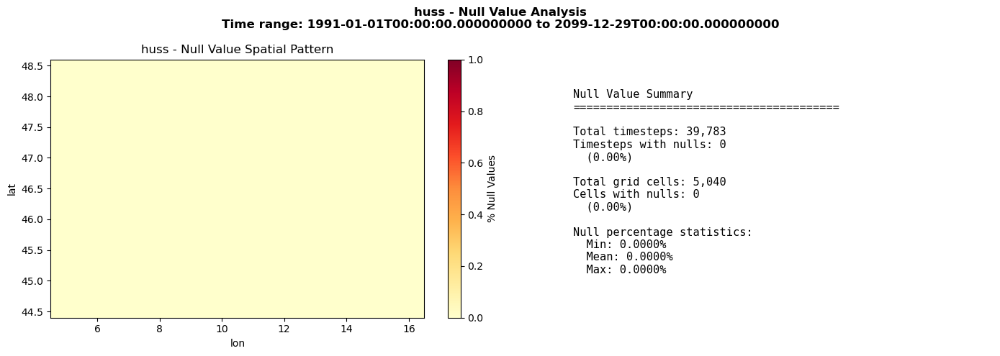

Computing null value statistics for hurs...
[########################################] | 100% Completed | 60.02 s
[########################################] | 100% Completed | 60.02 s
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 35.01 s


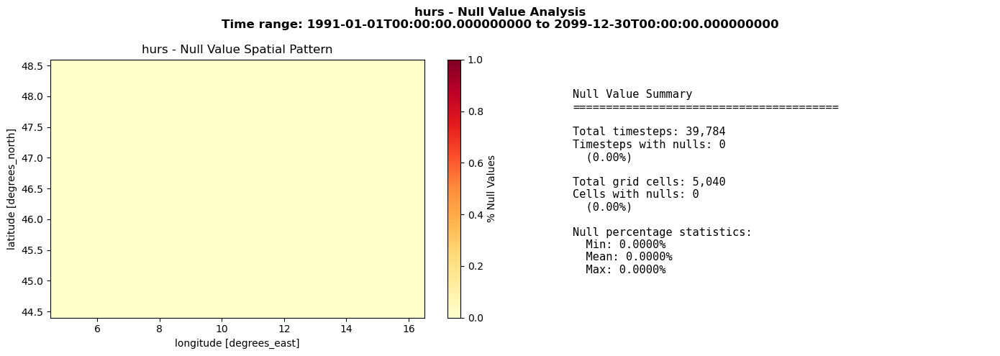

Computing null value statistics for pr...
[########################################] | 100% Completed | 115.03 s
[########################################] | 100% Completed | 115.03 s
[########################################] | 100% Completed | 75.02 s
[########################################] | 100% Completed | 75.02 s


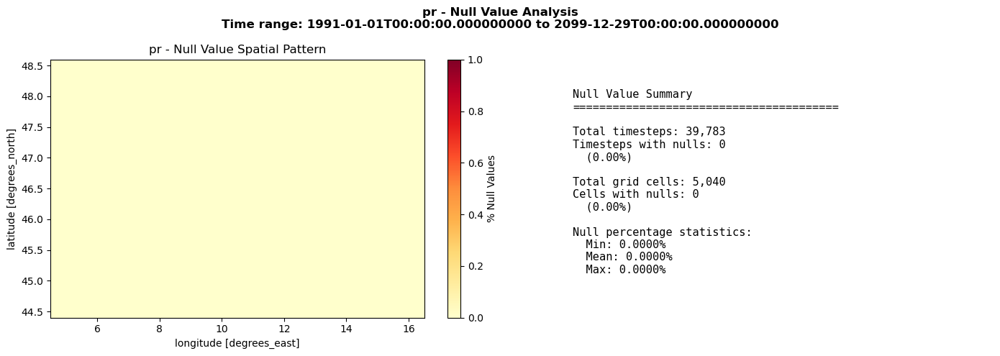

Computing null value statistics for rsds...
[########################################] | 100% Completed | 60.01 s
[########################################] | 100% Completed | 60.01 s
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 35.01 s


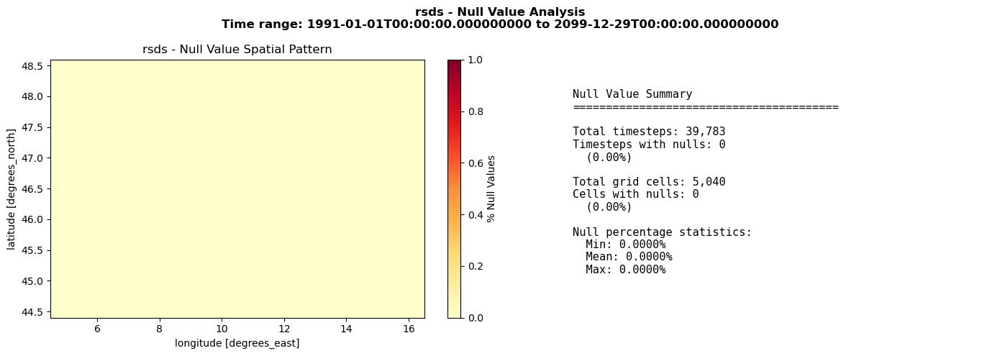

Computing null value statistics for sfcWind...
[########################################] | 100% Completed | 65.02 s
[########################################] | 100% Completed | 65.02 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


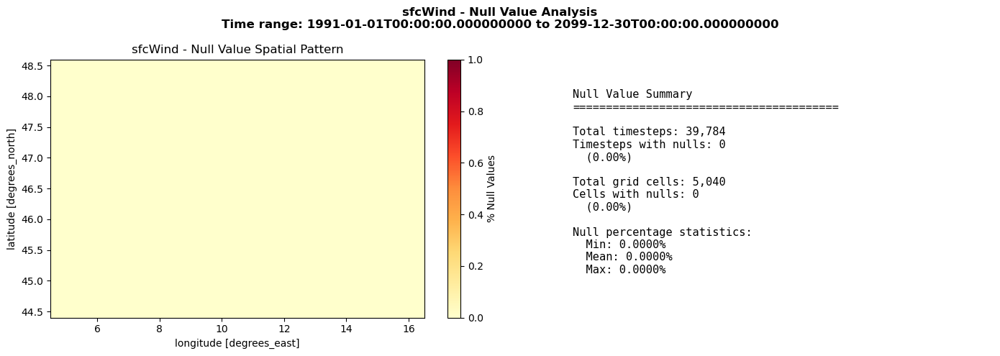

Computing null value statistics for tas...
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


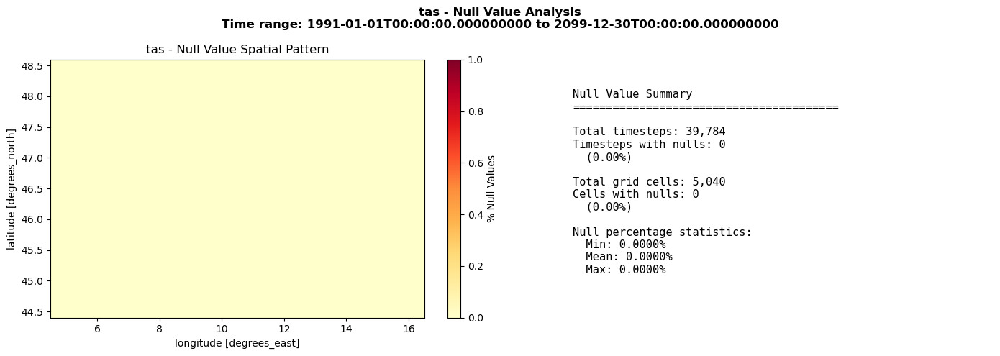

Computing null value statistics for tas_max...
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s


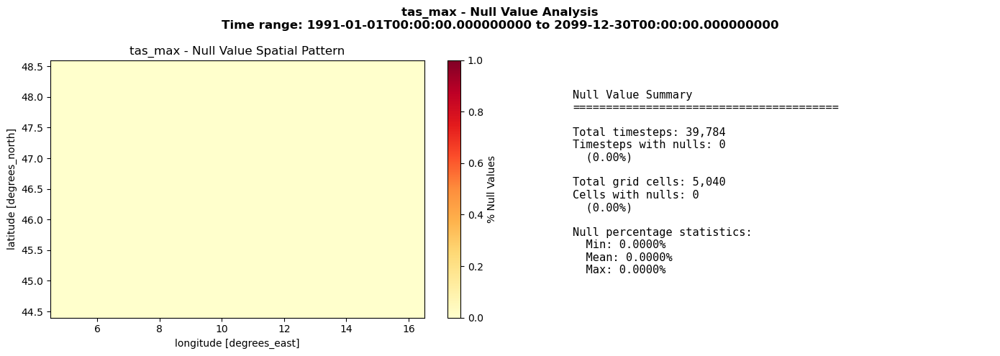

Computing null value statistics for tas_min...
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


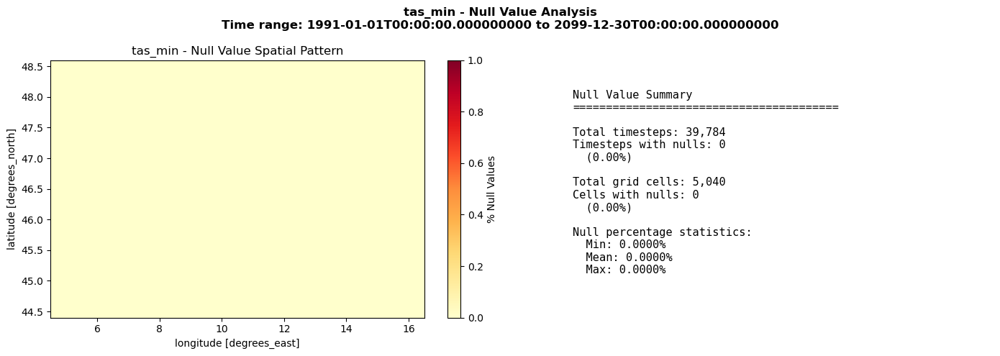

Computing null value statistics for clt...
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


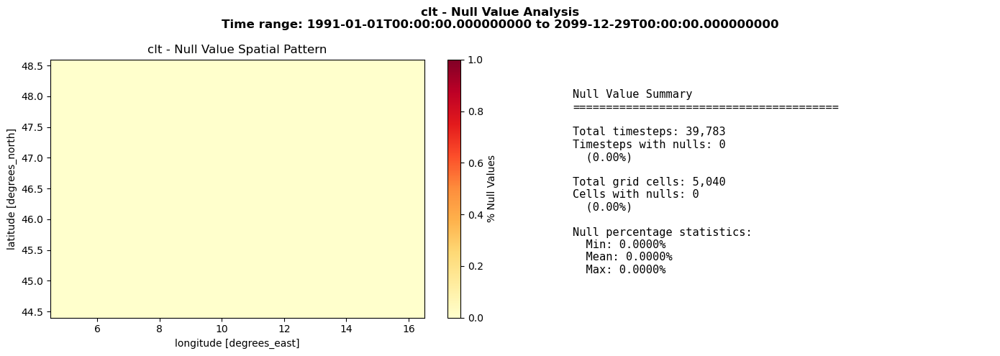

Computing null value statistics for psl...
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


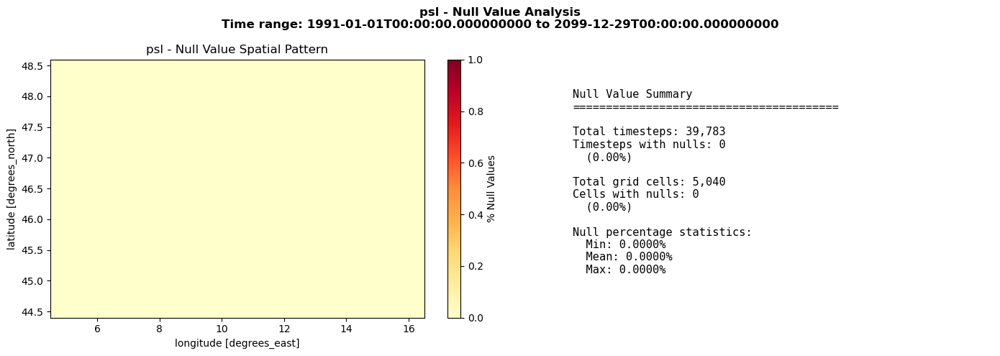

In [20]:
for var, ds in data_dict.items():
    plot_null_patterns(ds, var)

Computing spatial mean for huss...
[########################################] | 100% Completed | 60.02 s
[########################################] | 100% Completed | 60.02 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s
[#######################                 ] | 58% Completed | 10.00 ss

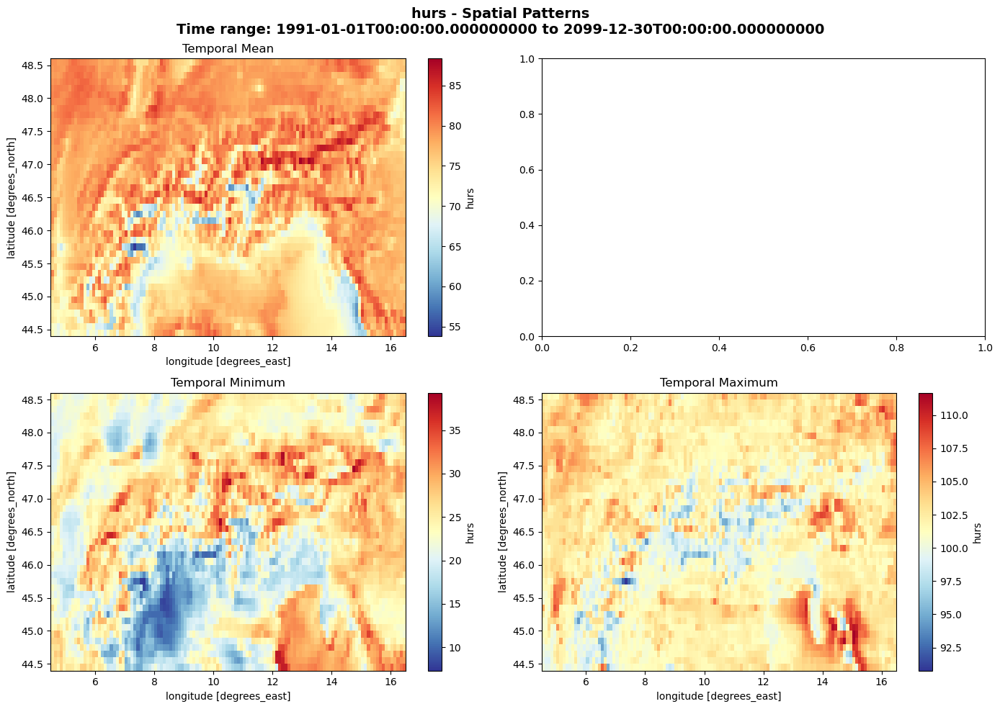


Summary Statistics for hurs
Overall mean: 76.6451
Spatial range: [7.3243, 111.6684]

Computing spatial mean for pr...
[########################################] | 100% Completed | 160.04 s
[########################################] | 100% Completed | 160.04 s
[########################################] | 100% Completed | 70.02 s
[########################################] | 100% Completed | 70.02 s
[########################################] | 100% Completed | 55.01 s



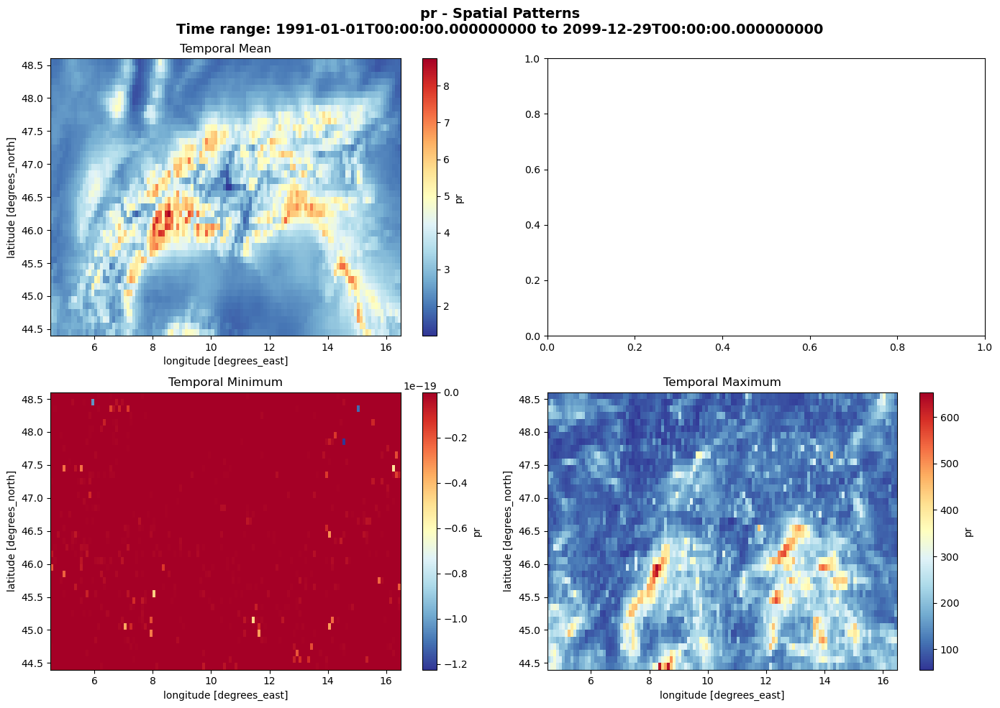


Summary Statistics for pr
Overall mean: 3.2485
Spatial range: [-0.0000, 652.9991]

Computing spatial mean for rsds...
[########################################] | 100% Completed | 75.02 s
[########################################] | 100% Completed | 75.02 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s


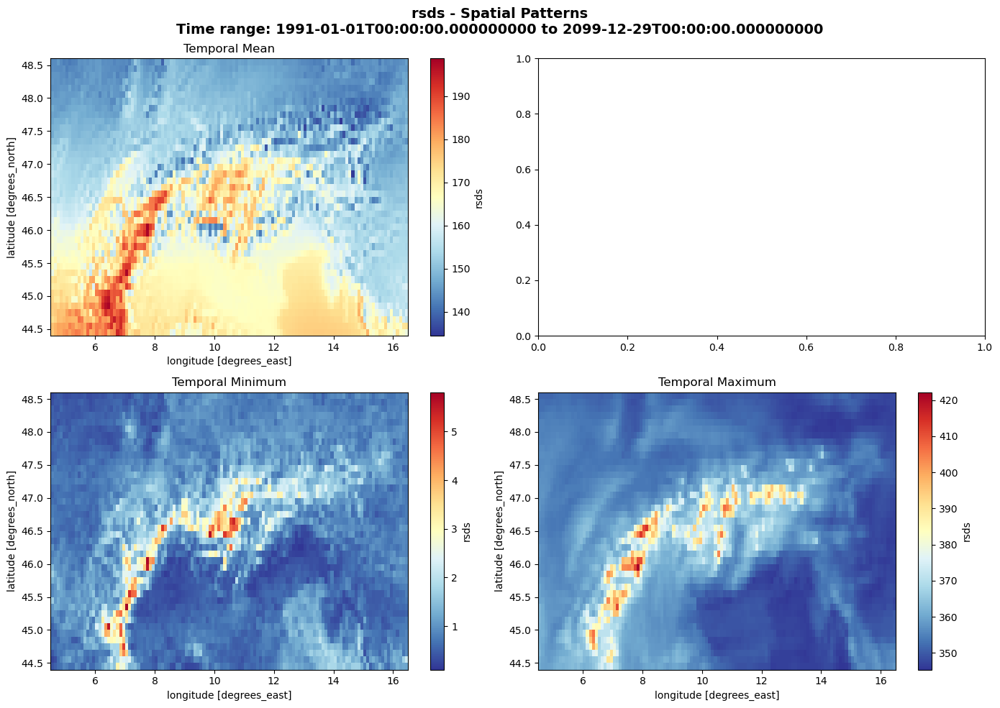


Summary Statistics for rsds
Overall mean: 158.8237
Spatial range: [0.1059, 422.1240]

Computing spatial mean for sfcWind...
[########################################] | 100% Completed | 80.02 s
[########################################] | 100% Completed | 80.02 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


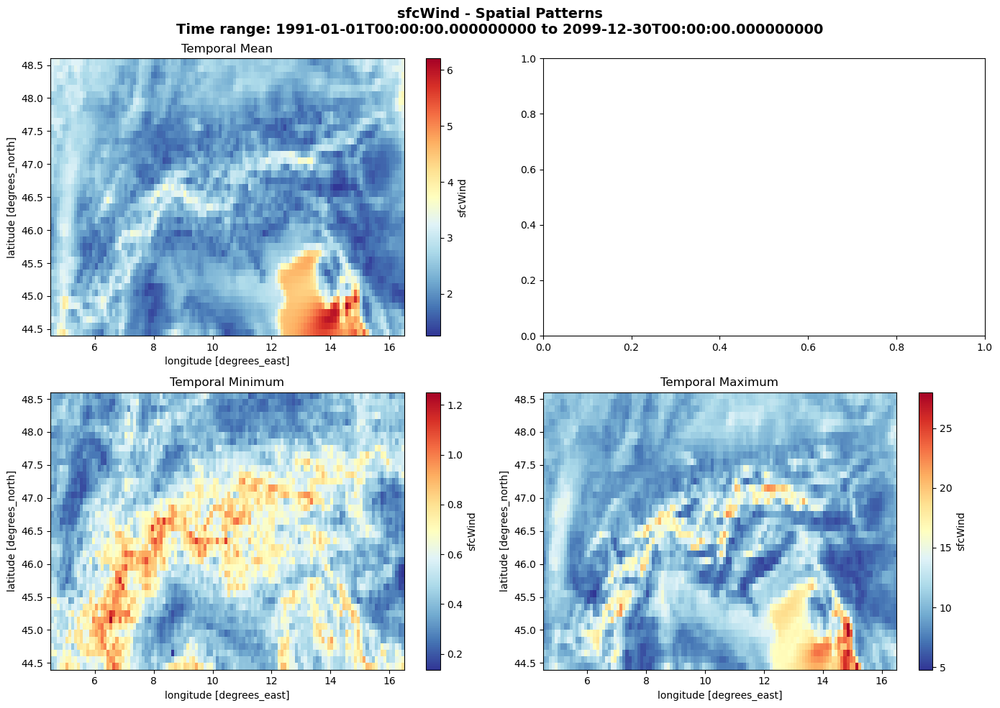


Summary Statistics for sfcWind
Overall mean: 2.4332
Spatial range: [0.1363, 28.0043]

Computing spatial mean for tas...
[########################################] | 100% Completed | 60.01 s
[########################################] | 100% Completed | 60.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 15.00 s
[########################################] | 100% Completed | 15.00 s


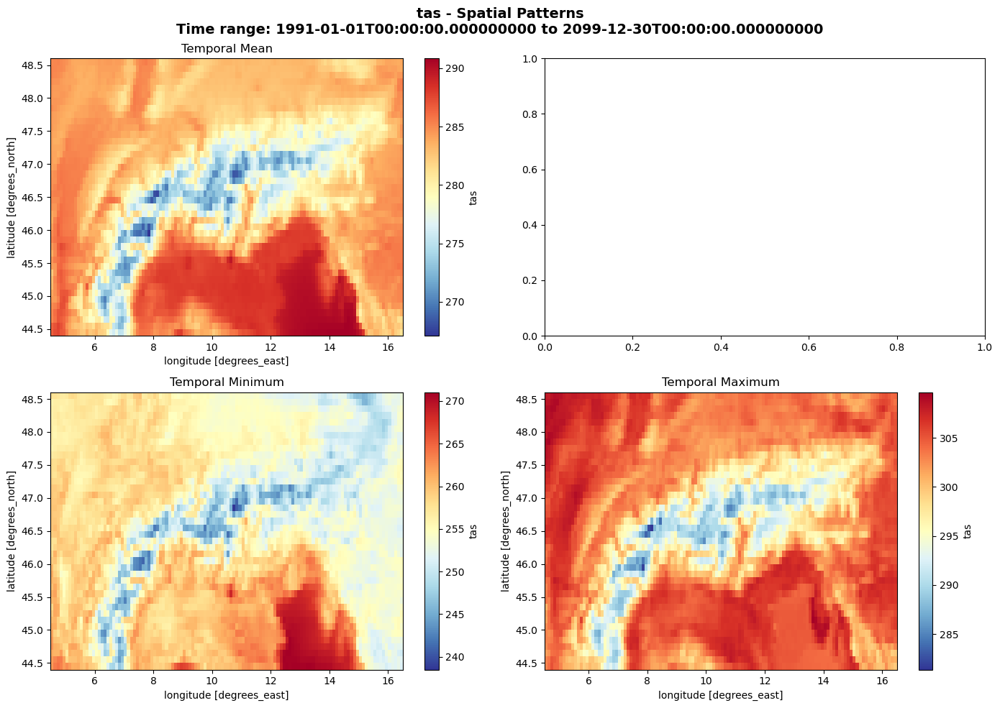


Summary Statistics for tas
Overall mean: 282.7984
Spatial range: [238.4971, 309.6389]

Computing spatial mean for tas_max...
[########################################] | 100% Completed | 70.02 s
[########################################] | 100% Completed | 70.02 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


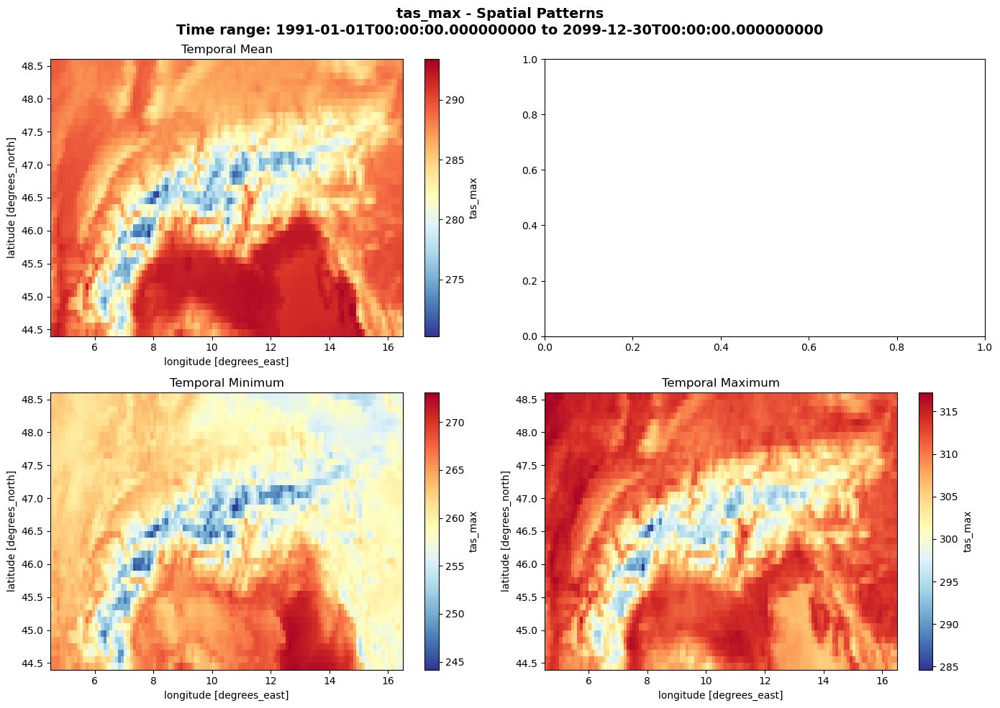


Summary Statistics for tas_max
Overall mean: 286.6893
Spatial range: [244.1839, 317.2031]

Computing spatial mean for tas_min...
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 15.00 s
[########################################] | 100% Completed | 15.00 s
[########################################] | 100% Completed | 10.00 s
[########################################] | 100% Completed | 10.00 s


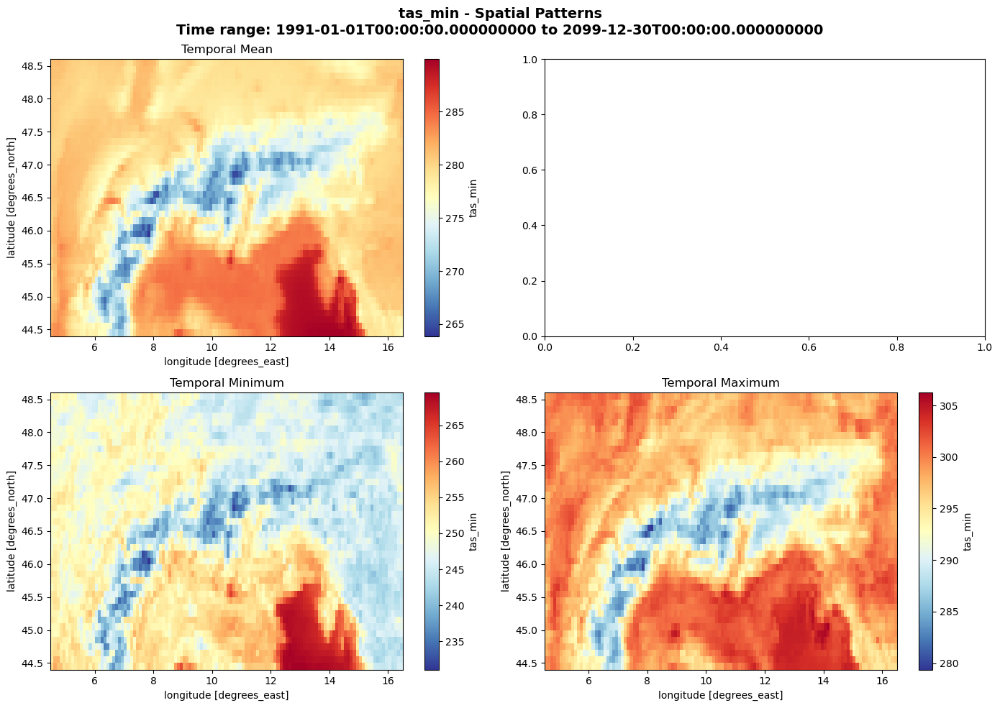


Summary Statistics for tas_min
Overall mean: 279.3075
Spatial range: [231.0693, 306.2350]

Computing spatial mean for clt...
[########################################] | 100% Completed | 65.02 s
[########################################] | 100% Completed | 65.02 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


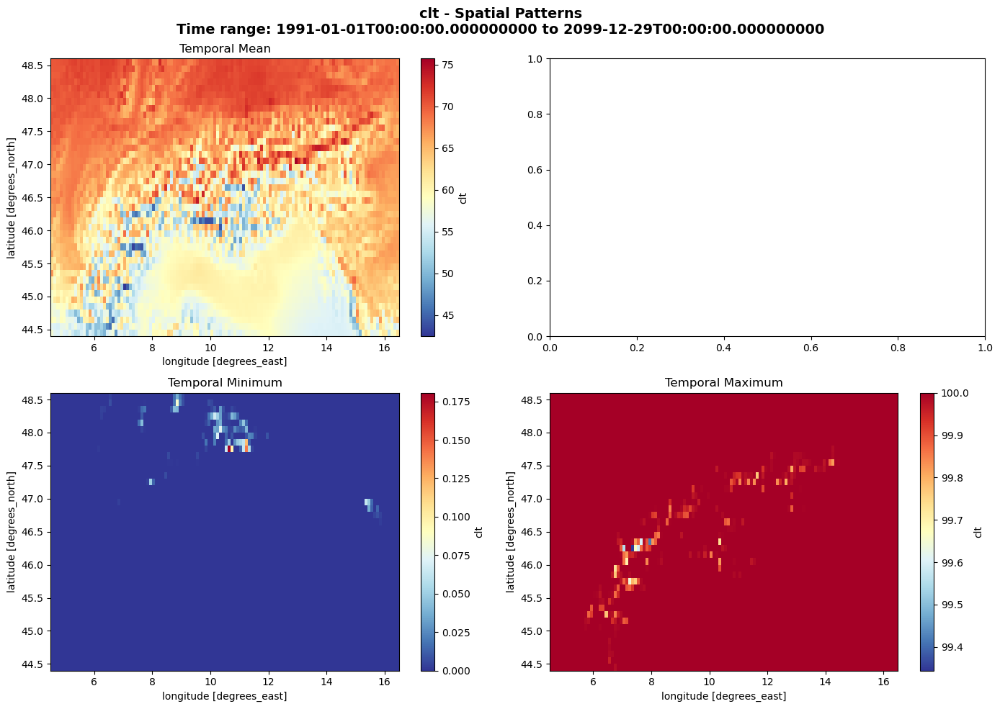


Summary Statistics for clt
Overall mean: 63.2683
Spatial range: [0.0000, 100.0000]

Computing spatial mean for psl...
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 15.00 s
[########################################] | 100% Completed | 15.00 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


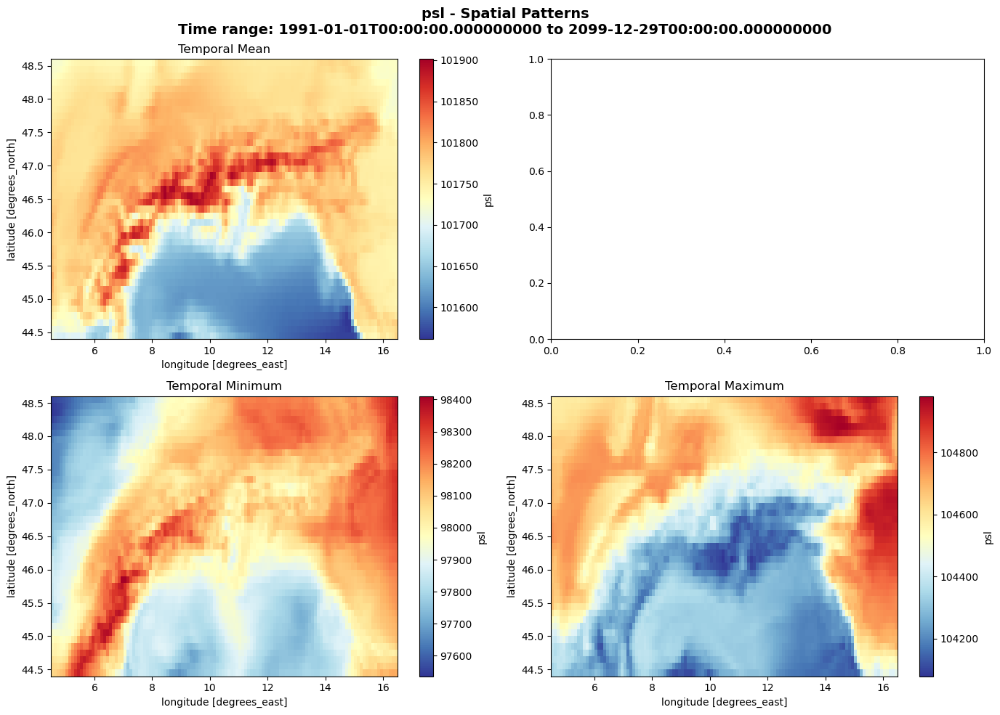


Summary Statistics for psl
Overall mean: 101741.7812
Spatial range: [97536.0781, 104980.6875]



In [22]:
for var, ds in data_dict.items():
    plot_spatial_stats(ds, var)

## rcp85

In [17]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
climate_model_scenario = "rcp85"

data_dict = load_prevah_data(climate_model_chain, climate_model_scenario)


Loading huss...
Loading hurs...
Loading pr...
Loading rsds...
Loading sfcWind...
Loading tas...
Loading tas_max...
Loading tas_min...
Loading clt...
Loading psl...

Loaded 10/10 variables
✓ All variables present!

huss:
  Variables: ['huss']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 39773}
  Time range: 1991-01-01T00:00:00.000000000 to 2099-12-19T00:00:00.000000000

hurs:
  Variables: ['hurs']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 39773}
  Time range: 1991-01-01T00:00:00.000000000 to 2099-12-19T00:00:00.000000000

pr:
  Variables: ['pr']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 39773}
  Time range: 1991-01-01T00:00:00.000000000 to 2099-12-19T00:00:00.000000000

rsds:
  Variables: ['rsds']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 39773}
  Time range: 1991-01-01T00:00:00.000000000 to 2099-12-19T00:00:00.000000000

sfcWind:
  Variables: ['sfcWind']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 39773}
  Time range: 1991-01-01T00:00:00.000000000 to 2099-12-19T00:00:00.

In [18]:
# Find timesteps where pr exceeds 500 mm/day in any grid cell
pr_ds = data_dict['pr']
pr_data = pr_ds['pr']

print("Searching for timesteps with pr > 500 mm/day...")
with ProgressBar(dt=5):
    # Find locations where pr exceeds 500 mm/day
    extreme_mask = (pr_data > 500).compute()

    # Get timesteps that have at least one grid cell exceeding threshold
    timesteps_with_extremes = extreme_mask.any(dim=['lat', 'lon'])
    extreme_times = pr_data.time[timesteps_with_extremes].values

    # Get max value per timestep for the extreme events
    if len(extreme_times) > 0:
        max_per_extreme_time = pr_data.sel(time=extreme_times).max(dim=['lat', 'lon']).compute()

print(f"\n{'='*60}")
print(f"Extreme Precipitation Events (> 500 mm/day)")
print(f"{'='*60}")
print(f"Number of timesteps with extremes: {len(extreme_times)}")
if len(extreme_times) > 0:
    print(f"\nTimesteps with pr > 500 mm/day:")
    for i, (time, max_val) in enumerate(zip(extreme_times, max_per_extreme_time.values)):
        print(f"  {i+1}. {time}: max = {max_val:.2f} mm/day")
else:
    print("No timesteps found with pr > 500 mm/day")
print(f"{'='*60}")

Searching for timesteps with pr > 500 mm/day...
[##########                              ] | 25% Completed | 10.00 s

[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 30.01 s

Extreme Precipitation Events (> 500 mm/day)
Number of timesteps with extremes: 21

Timesteps with pr > 500 mm/day:
  1. 2017-10-09T00:00:00.000000000: max = 670.23 mm/day
  2. 2021-09-28T00:00:00.000000000: max = 535.93 mm/day
  3. 2043-11-03T00:00:00.000000000: max = 525.61 mm/day
  4. 2059-10-14T00:00:00.000000000: max = 607.50 mm/day
  5. 2066-09-24T00:00:00.000000000: max = 550.93 mm/day
  6. 2072-10-23T00:00:00.000000000: max = 500.19 mm/day
  7. 2072-11-20T00:00:00.000000000: max = 597.98 mm/day
  8. 2073-12-05T00:00:00.000000000: max = 515.41 mm/day
  9. 2080-11-06T00:00:00.000000000: max = 547.97 mm/day
  10. 2085-11-17T00:00:00.000000000: max = 539.48 mm/day
  11. 2085-11-19T00:00:00.000000000: max = 542.83 mm/day
  12. 2087-09-25T00:00:00.000000000: max = 667.78 mm/day
  13. 2088-11-25T00:00:00.000000000: max = 631.13 mm/day
  14. 2089-1

Computing null value statistics for huss...
[########################################] | 100% Completed | 115.03 s
[                                        ] | 0% Completed | 677.31 us
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


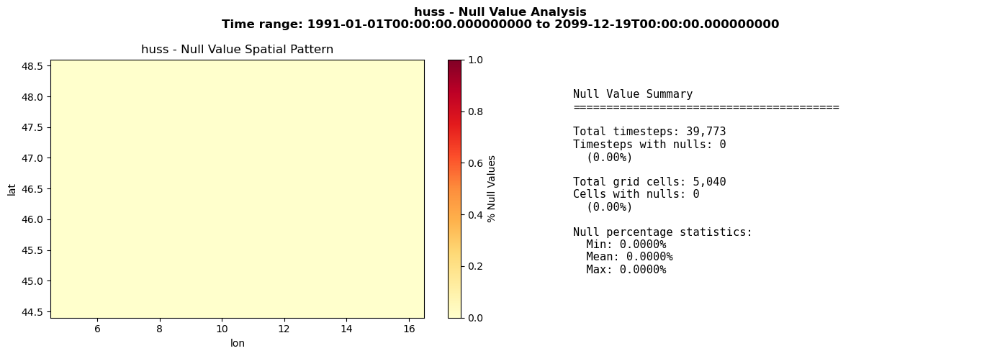

Computing null value statistics for hurs...
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


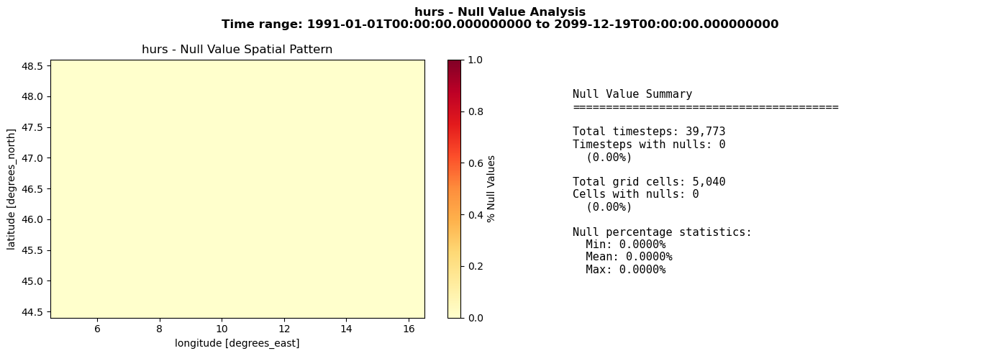

Computing null value statistics for pr...
[########################################] | 100% Completed | 205.05 s
[########################################] | 100% Completed | 205.05 s
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 45.01 s


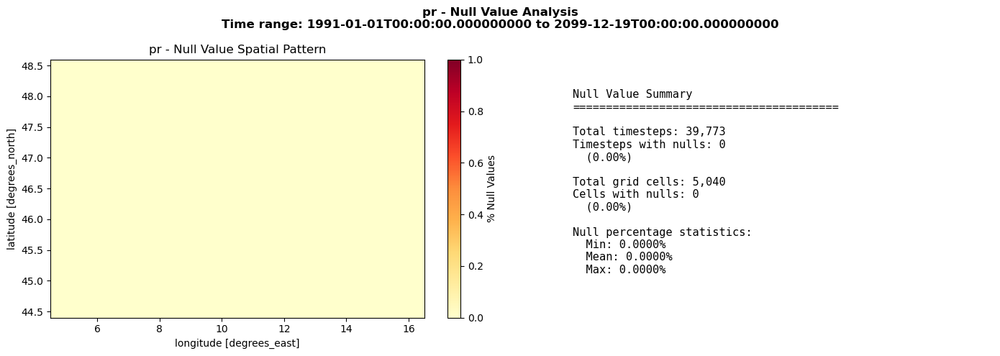

Computing null value statistics for rsds...
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 25.01 s



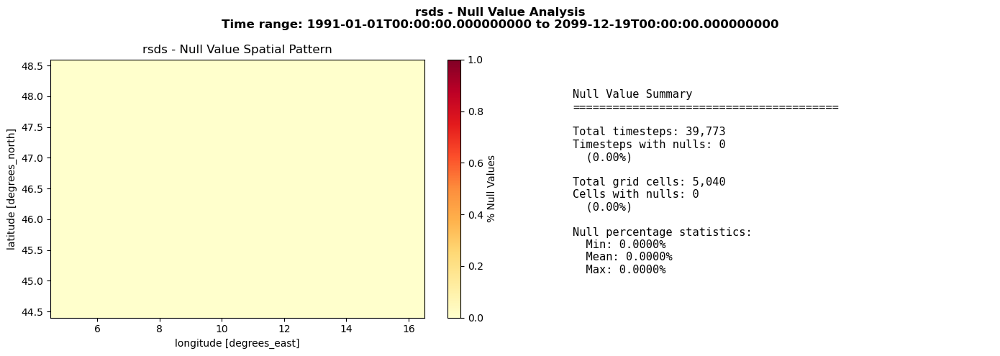

Computing null value statistics for sfcWind...
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 15.00 s
[########################################] | 100% Completed | 15.00 s


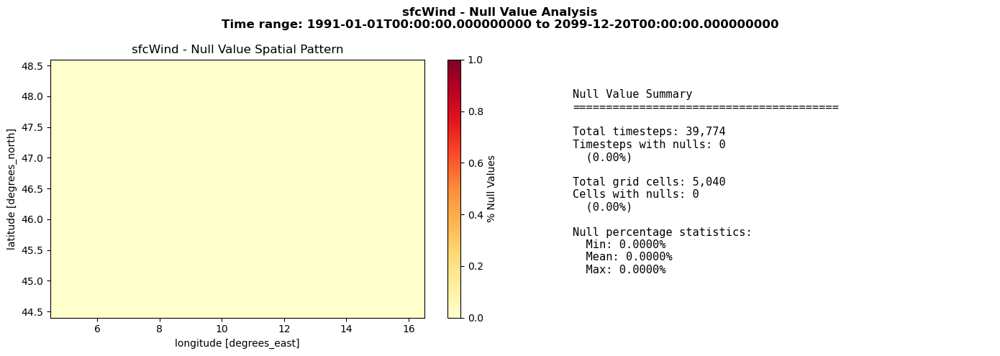

Computing null value statistics for tas...
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


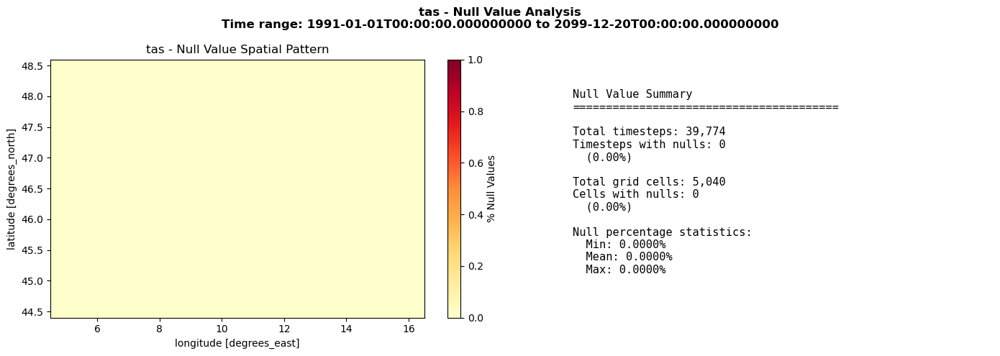

Computing null value statistics for tas_max...
[########################################] | 100% Completed | 165.04 s
[########################################] | 100% Completed | 165.04 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s


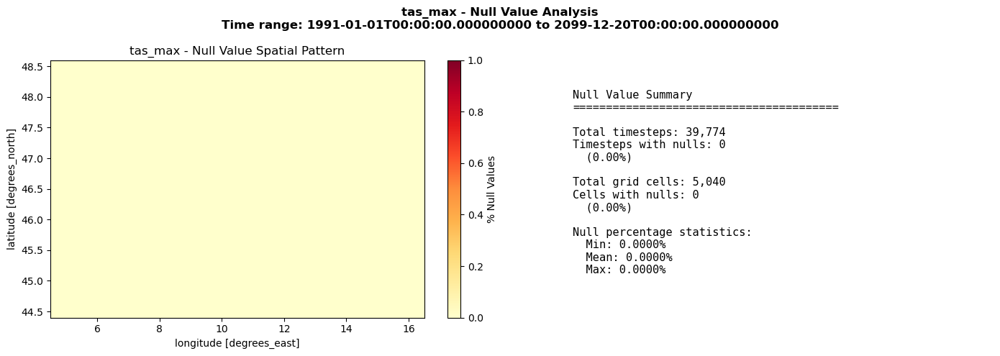

Computing null value statistics for tas_min...
[########################################] | 100% Completed | 175.04 s
[########################################] | 100% Completed | 175.04 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


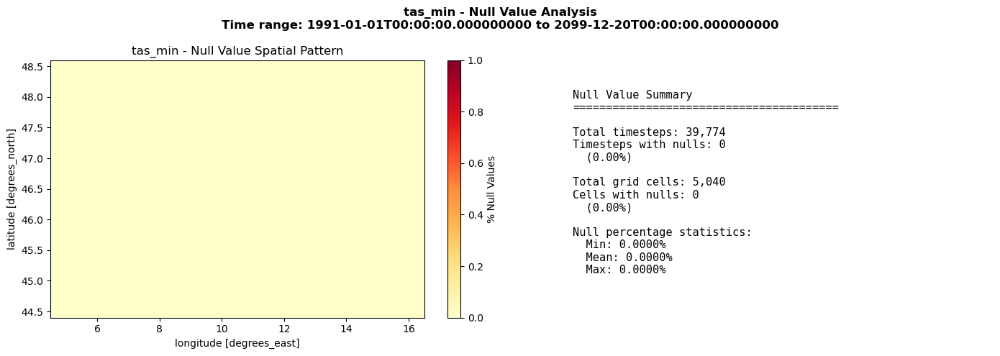

Computing null value statistics for clt...
[########################################] | 100% Completed | 65.02 s
[########################################] | 100% Completed | 65.02 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


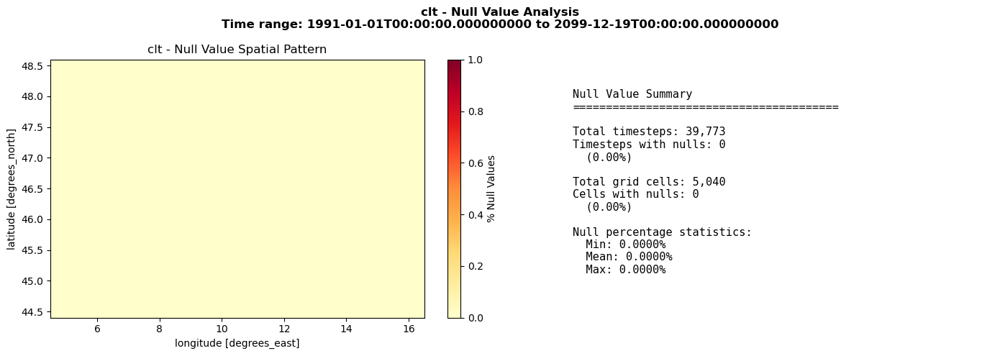

Computing null value statistics for psl...
[########################################] | 100% Completed | 60.02 s
[########################################] | 100% Completed | 60.02 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


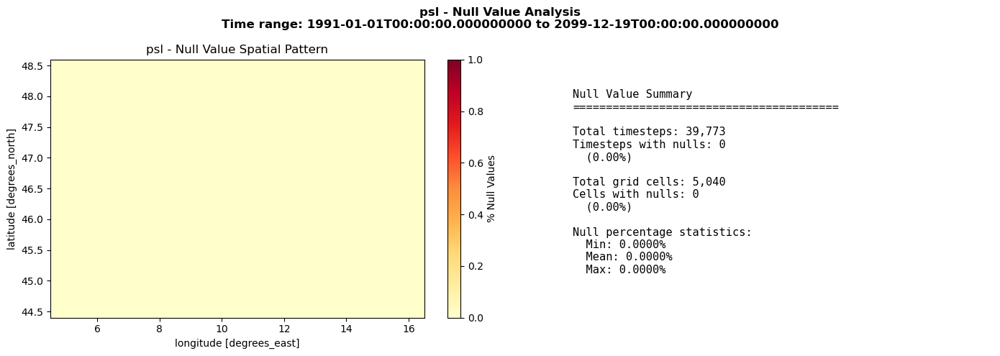

In [ ]:
for var, ds in data_dict.items():
    plot_null_patterns(ds, var)

Computing spatial mean for huss...
[                                        ] | 0% Completed | 448.95 us

[########################################] | 100% Completed | 105.03 s
[########################################] | 100% Completed | 105.03 s
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 55.01 s


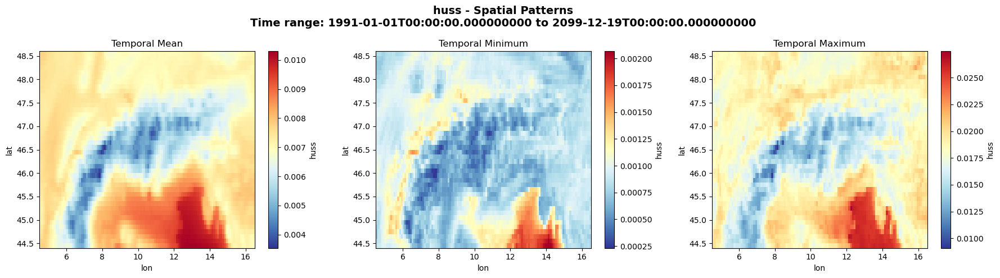


Summary Statistics for huss
Overall mean: 0.0071
Spatial range: [0.0002, 0.0275]

Computing spatial mean for hurs...
[########################################] | 100% Completed | 95.02 s
[########################################] | 100% Completed | 95.02 s
[########################################] | 100% Completed | 60.01 s
[########################################] | 100% Completed | 60.01 s
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 40.01 s


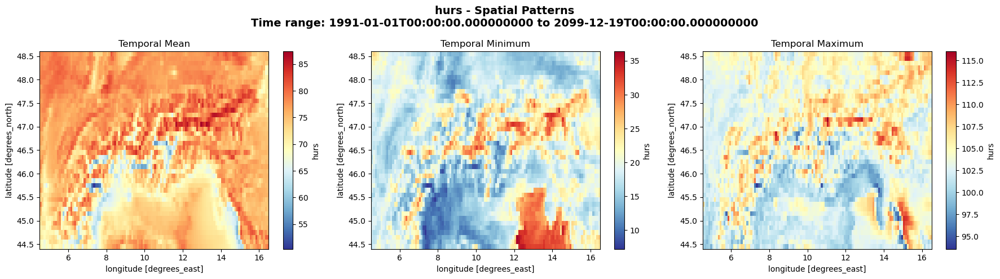


Summary Statistics for hurs
Overall mean: 74.8968
Spatial range: [7.2381, 116.0316]

Computing spatial mean for pr...
[########################################] | 100% Completed | 140.03 s
[########################################] | 100% Completed | 140.03 s
[########################################] | 100% Completed | 90.02 s
[########################################] | 100% Completed | 90.02 s
[########################################] | 100% Completed | 105.02 s
[########################################] | 100% Completed | 105.02 s


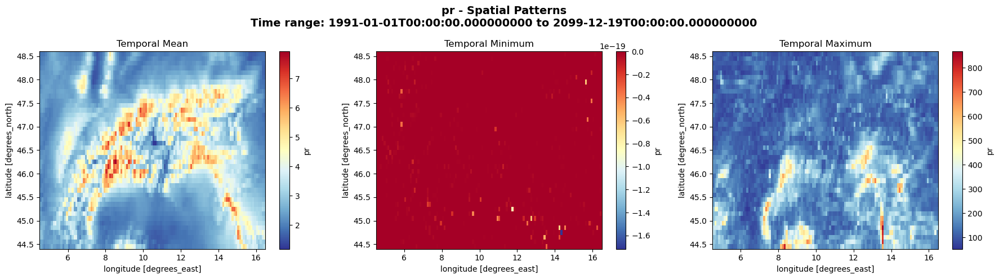


Summary Statistics for pr
Overall mean: 3.1501
Spatial range: [-0.0000, 867.4866]

Computing spatial mean for rsds...
[########################################] | 100% Completed | 85.02 s
[########################################] | 100% Completed | 85.02 s
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 45.01 s
[########################################] | 100% Completed | 45.01 s


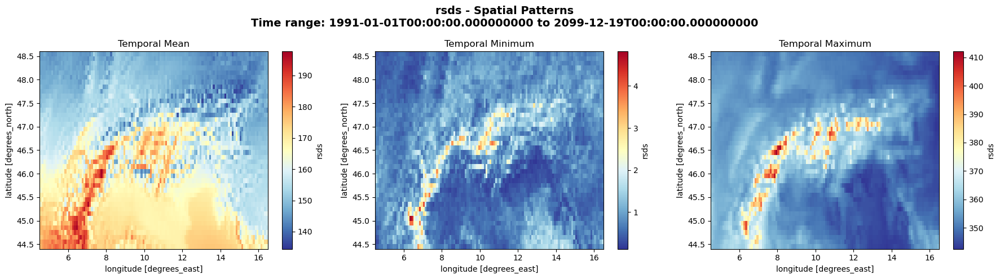


Summary Statistics for rsds
Overall mean: 159.8683
Spatial range: [0.1272, 412.0629]

Computing spatial mean for sfcWind...
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


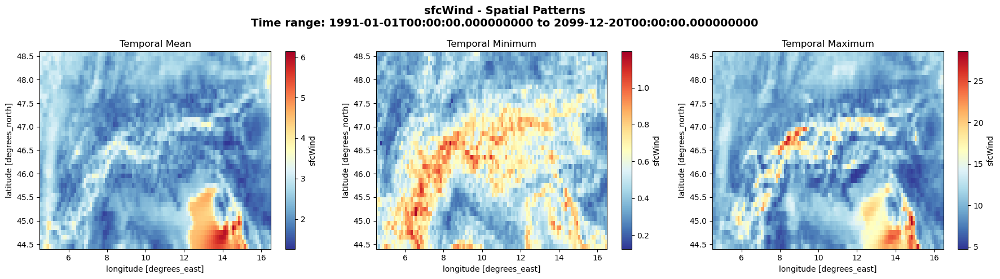


Summary Statistics for sfcWind
Overall mean: 2.4418
Spatial range: [0.1263, 28.5759]

Computing spatial mean for tas...
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


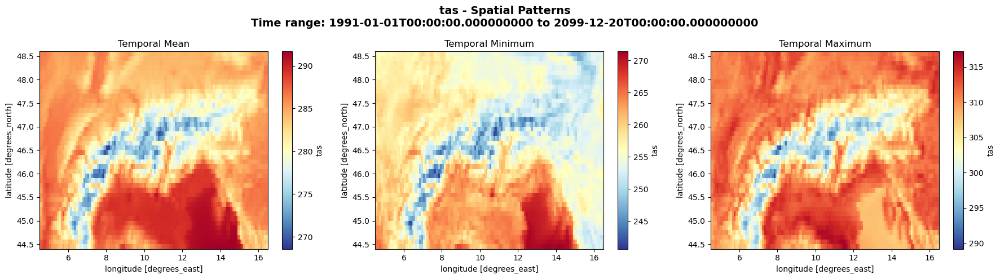


Summary Statistics for tas
Overall mean: 284.0734
Spatial range: [240.6818, 317.2029]

Computing spatial mean for tas_max...
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 50.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s


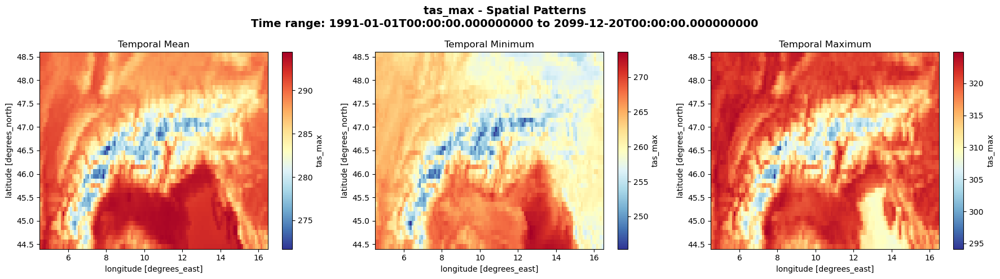


Summary Statistics for tas_max
Overall mean: 288.0808
Spatial range: [245.3293, 324.8733]

Computing spatial mean for tas_min...
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


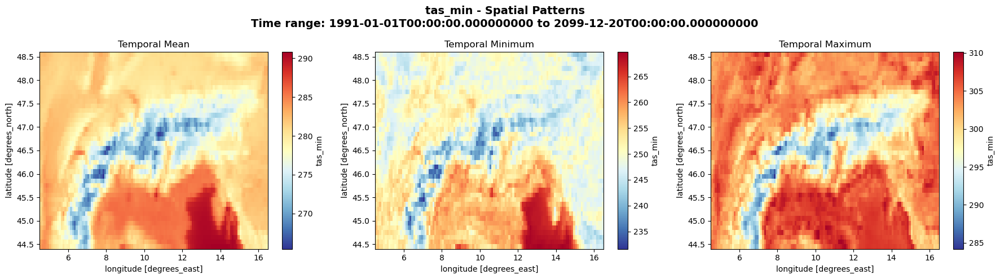


Summary Statistics for tas_min
Overall mean: 280.4990
Spatial range: [231.6277, 310.1091]

Computing spatial mean for clt...
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


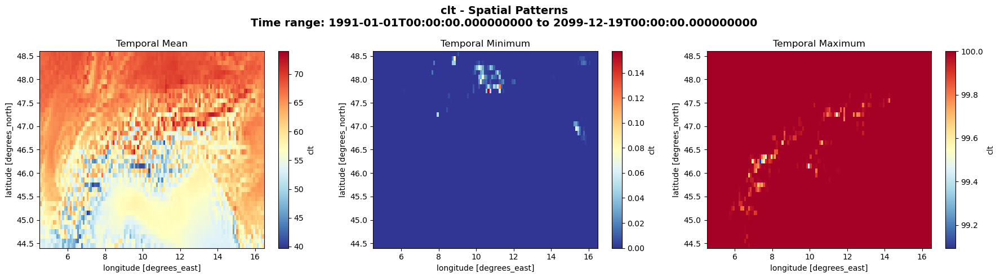


Summary Statistics for clt
Overall mean: 60.8107
Spatial range: [0.0000, 100.0000]

Computing spatial mean for psl...
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 55.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


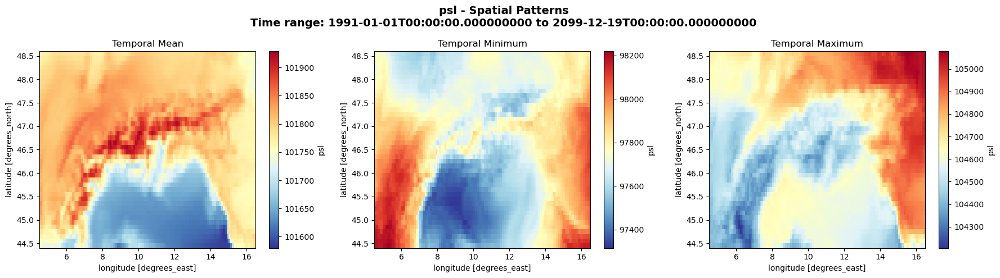


Summary Statistics for psl
Overall mean: 101769.1484
Spatial range: [97315.1953, 105077.7812]



In [ ]:
for var, ds in data_dict.items():
    plot_spatial_stats(ds, var)

# MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1

## rcp26

In [12]:
climate_model_chain = "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1"
climate_model_scenario = "rcp26"

data_dict = load_prevah_data(climate_model_chain, climate_model_scenario)


Loading huss...
Loading hurs...
Loading pr...
Loading rsds...
Loading hurs...
Loading pr...
Loading rsds...
Loading sfcWind...
Loading tas...
Loading tas_max...
Loading tas_min...
Loading sfcWind...
Loading tas...
Loading tas_max...
Loading tas_min...
Loading clt...
Loading psl...

Loaded 10/10 variables
✓ All variables present!

huss:
  Variables: ['huss']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

hurs:
  Variables: ['hurs']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

pr:
  Variables: ['pr']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

rsds:
  Variables: ['rsds']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

sfcWind:
  Variables: ['sfcWind']
  

Computing null value statistics for huss...
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


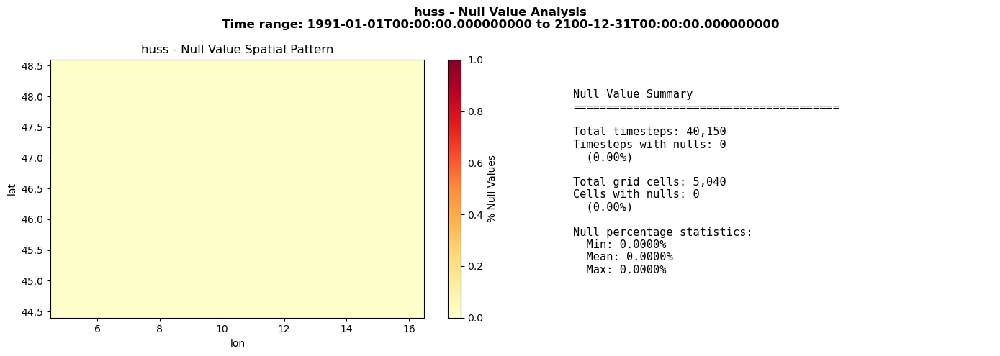

Computing null value statistics for hurs...
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 25.05 s
[########################################] | 100% Completed | 25.05 s


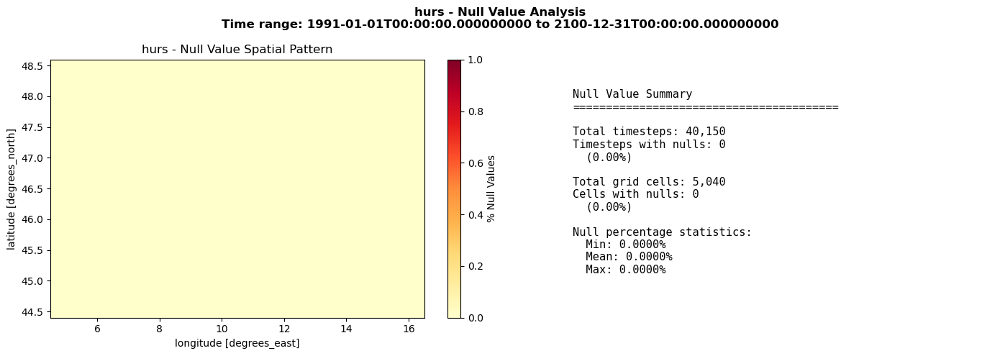

Computing null value statistics for pr...
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


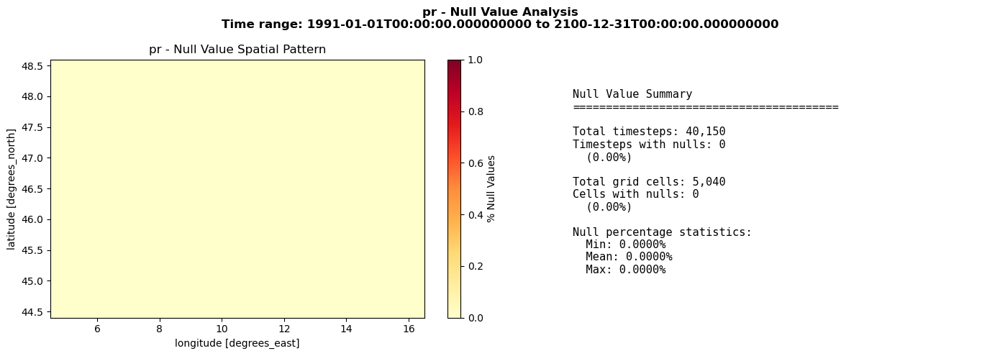

Computing null value statistics for rsds...
[########################################] | 100% Completed | 30.02 s
[########################################] | 100% Completed | 30.02 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


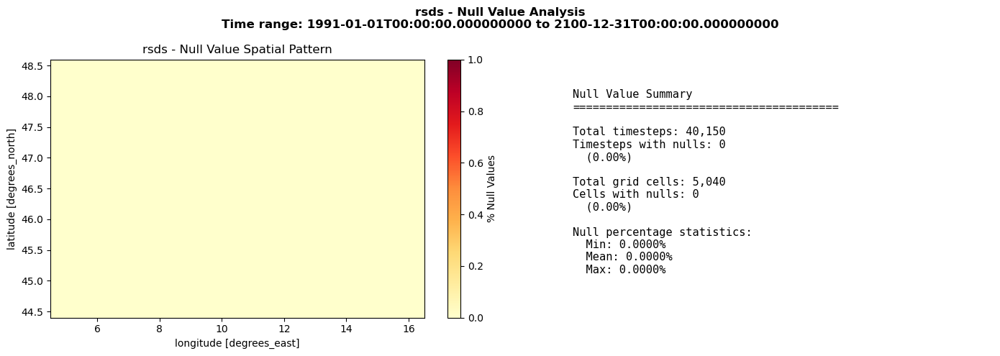

Computing null value statistics for sfcWind...
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


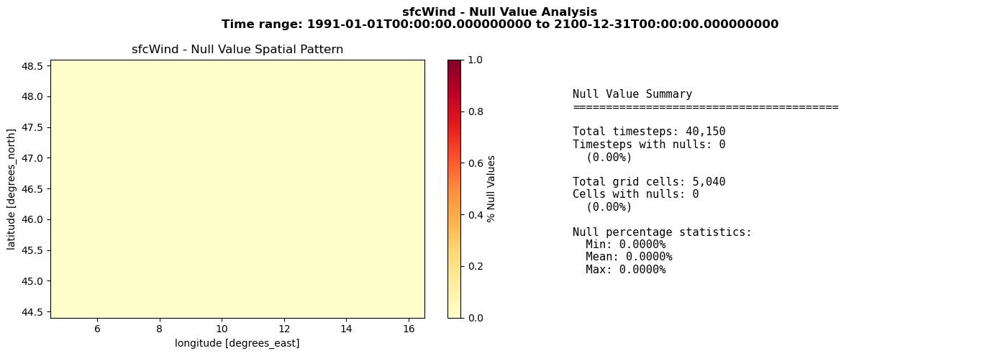

Computing null value statistics for tas...
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s


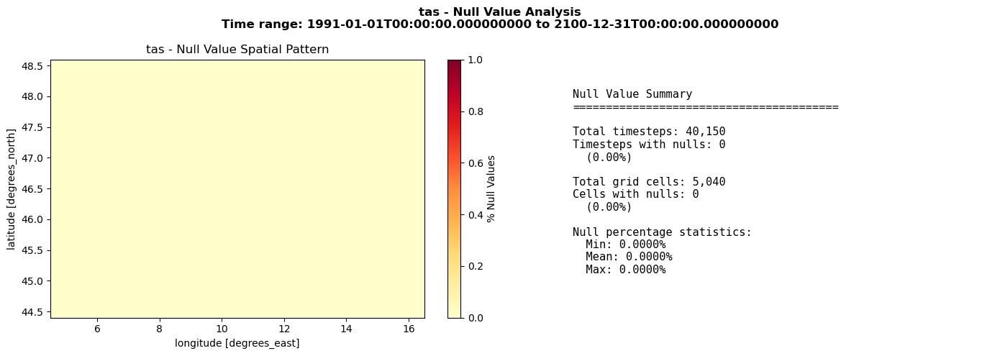

Computing null value statistics for tas_max...
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


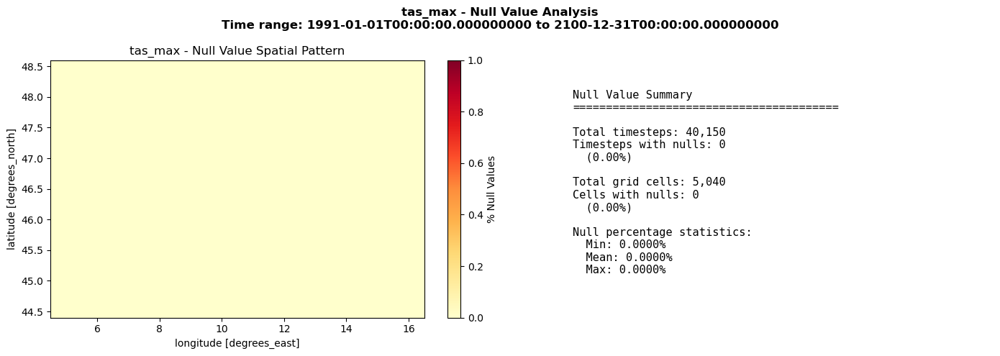

Computing null value statistics for tas_min...
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s


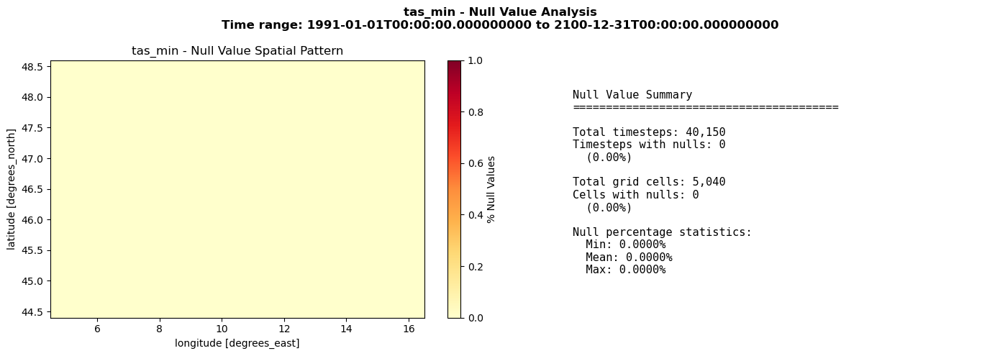

Computing null value statistics for clt...
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


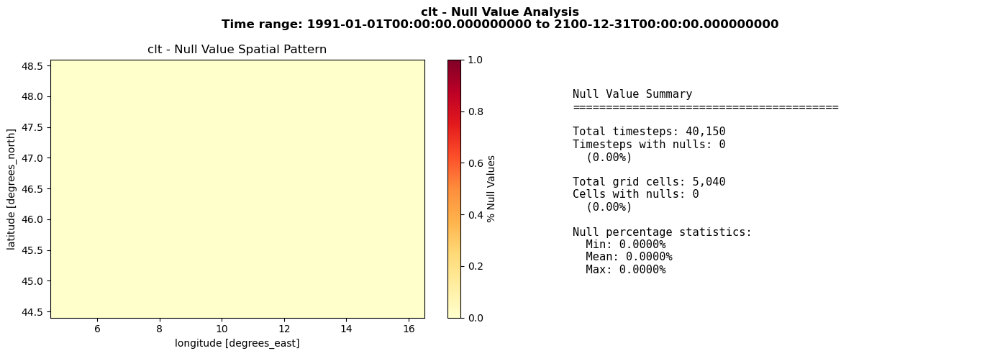

Computing null value statistics for psl...
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


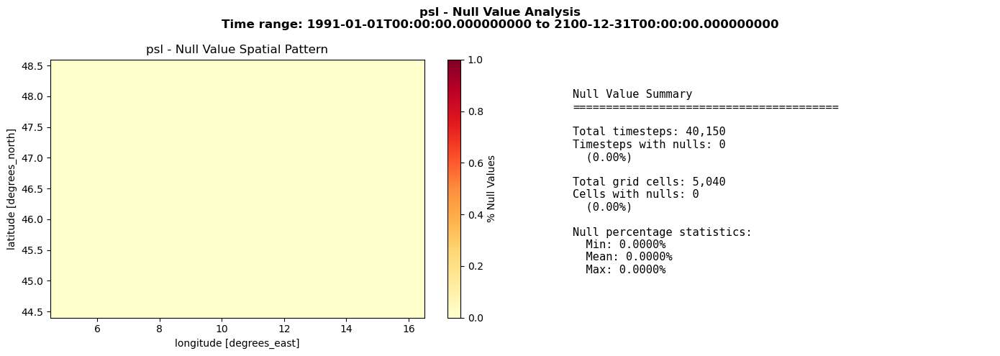

In [13]:
for var, ds in data_dict.items():
    plot_null_patterns(ds, var)

Computing spatial mean for huss...
[#################################       ] | 83% Completed | 20.01 ss

[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s


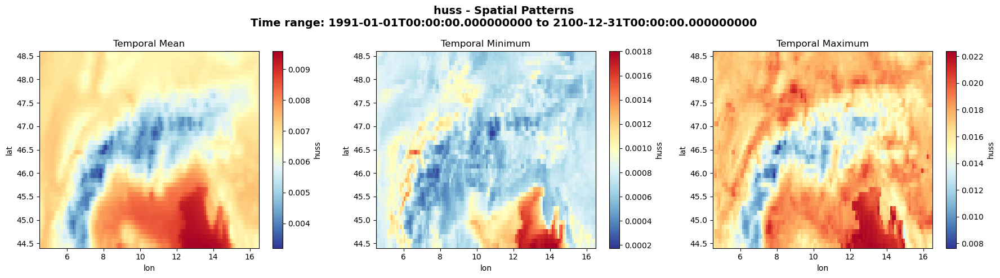


Summary Statistics for huss
Overall mean: 0.0067
Spatial range: [0.0002, 0.0224]

Computing spatial mean for hurs...
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


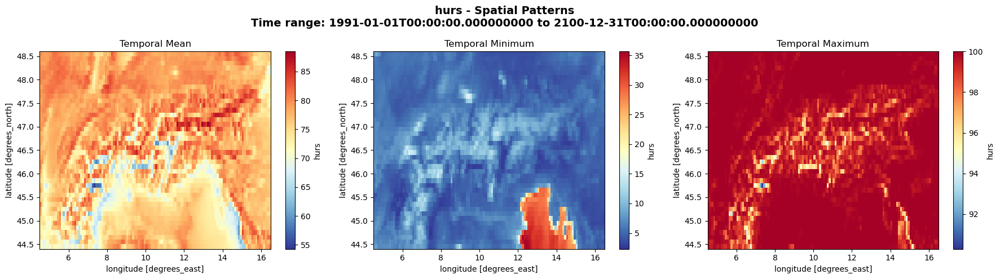


Summary Statistics for hurs
Overall mean: 76.7954
Spatial range: [2.3336, 100.0000]

Computing spatial mean for pr...
[########################################] | 100% Completed | 35.03 s
[########################################] | 100% Completed | 35.03 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 10.01 s


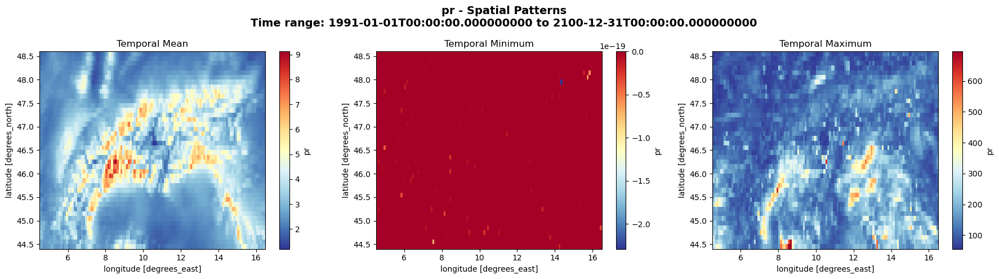


Summary Statistics for pr
Overall mean: 3.2858
Spatial range: [-0.0000, 695.3347]

Computing spatial mean for rsds...
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


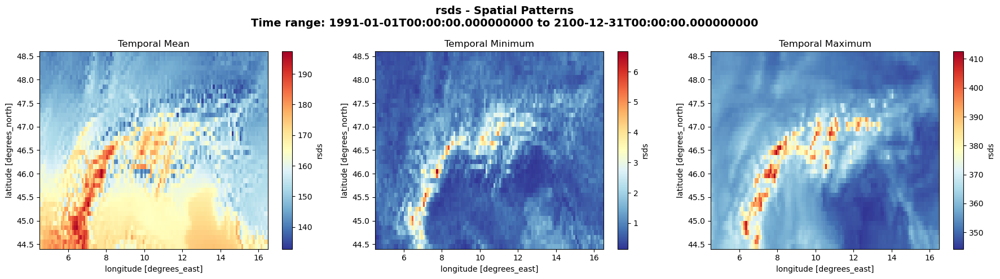


Summary Statistics for rsds
Overall mean: 157.3010
Spatial range: [0.1472, 412.5380]

Computing spatial mean for sfcWind...
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


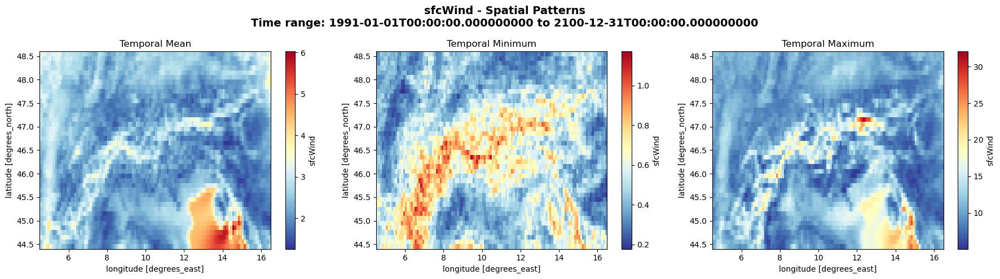


Summary Statistics for sfcWind
Overall mean: 2.4389
Spatial range: [0.1774, 32.0664]

Computing spatial mean for tas...
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


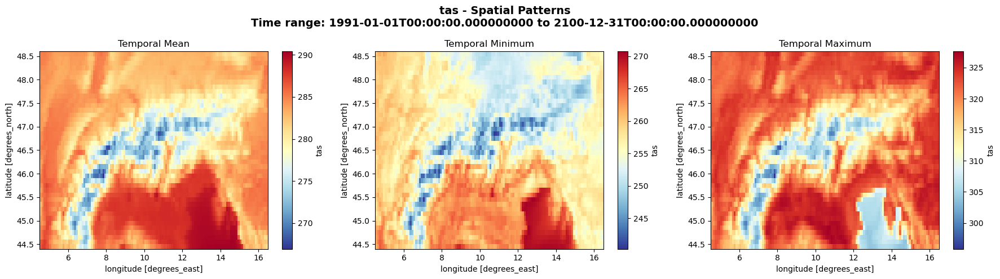


Summary Statistics for tas
Overall mean: 282.6572
Spatial range: [240.2983, 327.5998]

Computing spatial mean for tas_max...
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


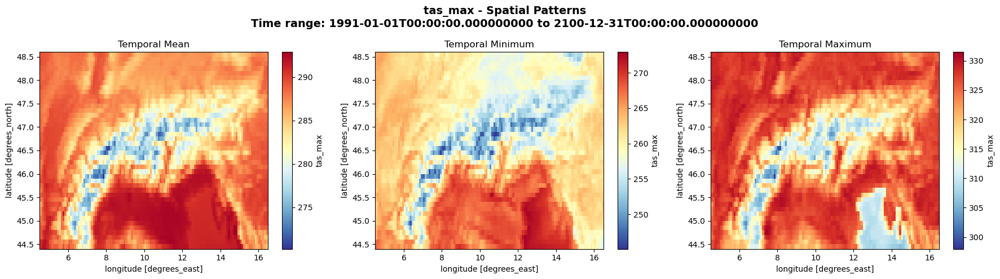


Summary Statistics for tas_max
Overall mean: 286.5565
Spatial range: [245.1154, 331.4802]

Computing spatial mean for tas_min...
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s


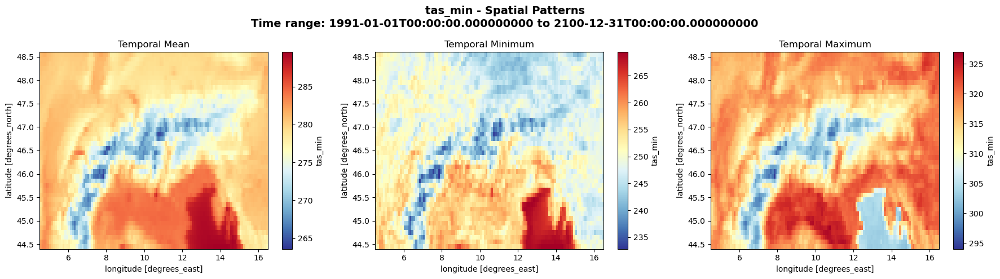


Summary Statistics for tas_min
Overall mean: 279.1384
Spatial range: [232.8173, 326.9586]

Computing spatial mean for clt...
[########################################] | 100% Completed | 35.03 s
[########################################] | 100% Completed | 35.03 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 15.01 s


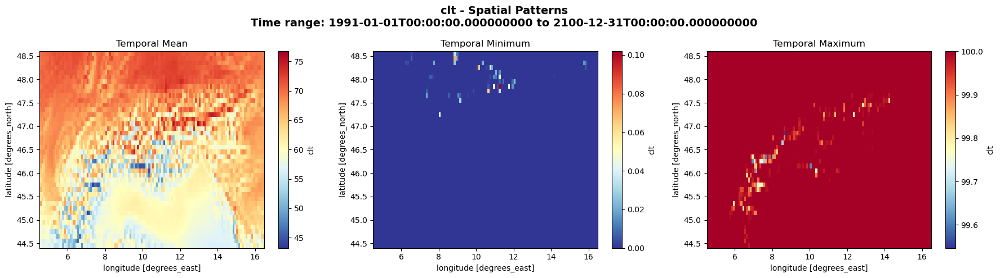


Summary Statistics for clt
Overall mean: 64.0032
Spatial range: [0.0000, 100.0000]

Computing spatial mean for psl...
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.03 s
[########################################] | 100% Completed | 20.03 s


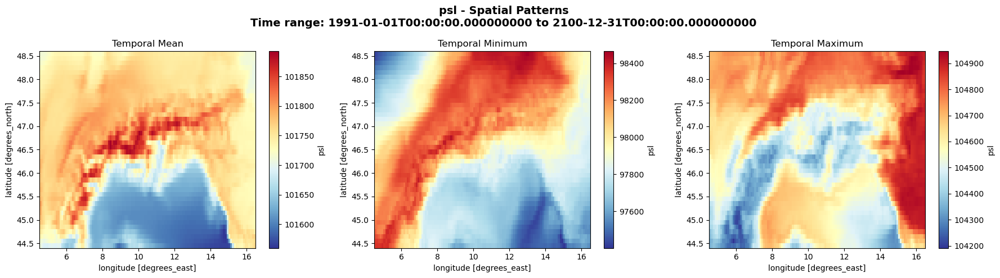


Summary Statistics for psl
Overall mean: 101732.8672
Spatial range: [97401.1484, 104945.9844]



In [14]:
for var, ds in data_dict.items():
    plot_spatial_stats(ds, var)

## rcp85

In [9]:
climate_model_chain = "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1"
climate_model_scenario = "rcp85"

data_dict = load_prevah_data(climate_model_chain, climate_model_scenario)


Loading huss...
Loading hurs...
Loading pr...
Loading rsds...
Loading sfcWind...
Loading tas...
Loading tas_max...
Loading tas_min...
Loading clt...
Loading psl...

Loaded 10/10 variables
✓ All variables present!

huss:
  Variables: ['huss']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

hurs:
  Variables: ['hurs']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

pr:
  Variables: ['pr']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

rsds:
  Variables: ['rsds']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

sfcWind:
  Variables: ['sfcWind']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.

In [ ]:
# Find timesteps where pr exceeds 500 mm/day in any grid cell
pr_ds = data_dict['pr']
pr_data = pr_ds['pr']

threshold = 400  # mm/day
print(f"Searching for timesteps with pr > {threshold} mm/day...")
with ProgressBar(dt=5):
    # Find locations where pr exceeds 500 mm/day
    extreme_mask = (pr_data > threshold).compute()
    # Get timesteps that have at least one grid cell exceeding threshold
    timesteps_with_extremes = extreme_mask.any(dim=['lat', 'lon'])
    extreme_times = pr_data.time[timesteps_with_extremes].values

    # Get max value per timestep for the extreme events
    if len(extreme_times) > 0:
        max_per_extreme_time = pr_data.sel(time=extreme_times).max(dim=['lat', 'lon']).compute()

print(f"\n{'='*60}")
print(f"Extreme Precipitation Events (> {threshold} mm/day)")
print(f"{'='*60}")
print(f"Number of timesteps with extremes: {len(extreme_times)}")
if len(extreme_times) > 0:
    print(f"\nTimesteps with pr > {threshold} mm/day:")
    for i, (time, max_val) in enumerate(zip(extreme_times, max_per_extreme_time.values)):
        print(f"  {i+1}. {time}: max = {max_val:.2f} mm/day")
else:
    print(f"No timesteps found with pr > {threshold} mm/day")
print(f"{'='*60}")

Searching for timesteps with pr > 500 mm/day...
[########################################] | 100% Completed | 55.03 s
[########################################] | 100% Completed | 30.02 s

Extreme Precipitation Events (> 500 mm/day)
Number of timesteps with extremes: 12

Timesteps with pr > 500 mm/day:
  1. 1991-10-19T00:00:00.000000000: max = 566.24 mm/day
  2. 2022-11-01T00:00:00.000000000: max = 794.90 mm/day
  3. 2031-10-22T00:00:00.000000000: max = 538.60 mm/day
  4. 2035-11-16T00:00:00.000000000: max = 502.40 mm/day
  5. 2037-10-10T00:00:00.000000000: max = 506.55 mm/day
  6. 2044-12-07T00:00:00.000000000: max = 570.93 mm/day
  7. 2063-10-21T00:00:00.000000000: max = 865.80 mm/day
  8. 2076-12-27T00:00:00.000000000: max = 522.64 mm/day
  9. 2092-11-05T00:00:00.000000000: max = 556.36 mm/day
  10. 2094-11-07T00:00:00.000000000: max = 522.37 mm/day
  11. 2094-11-11T00:00:00.000000000: max = 522.19 mm/day
  12. 2099-11-21T00:00:00.000000000: max = 650.78 mm/day


Computing null value statistics for huss...
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 30.01 s
[########################################] | 100% Completed | 25.02 s
[########################################] | 100% Completed | 25.02 s


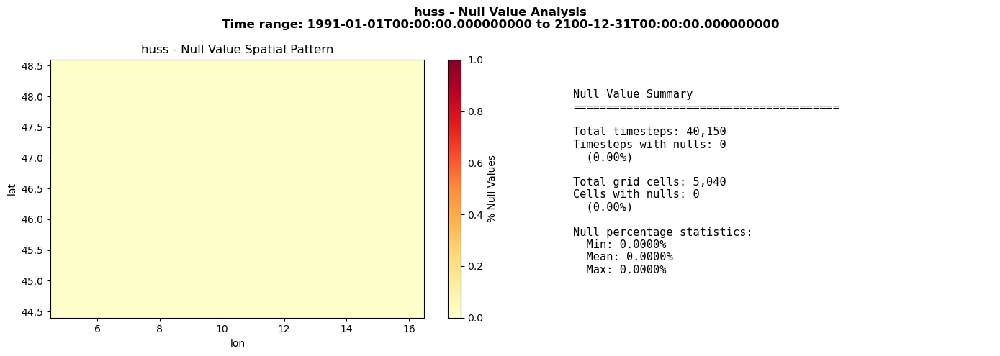

Computing null value statistics for hurs...
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s


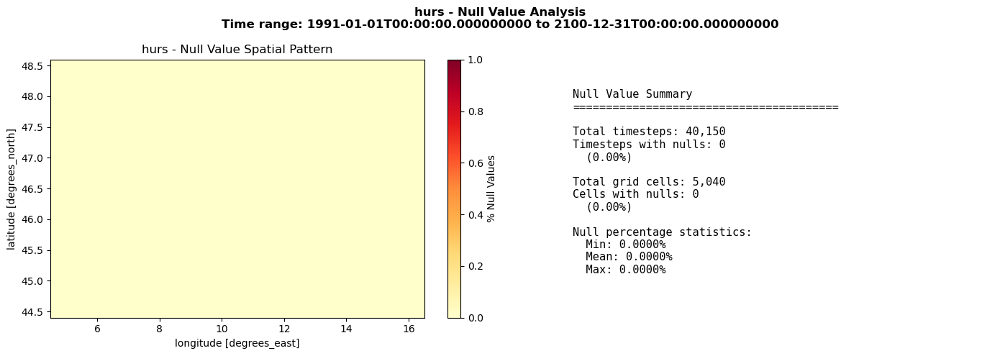

Computing null value statistics for pr...
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 10.01 s


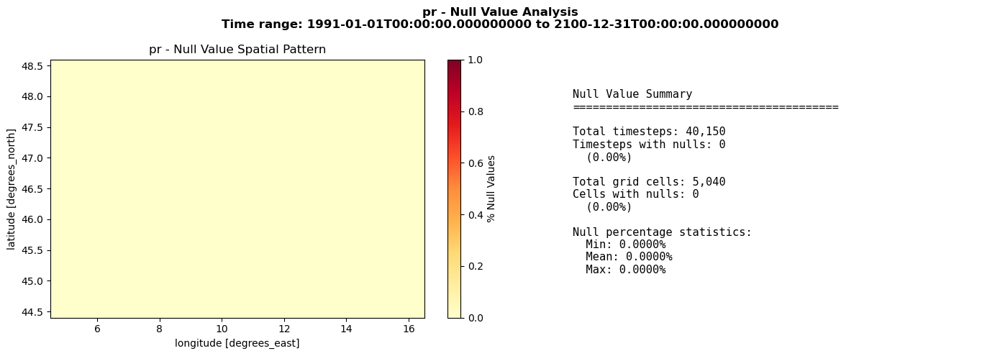

Computing null value statistics for rsds...
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 25.01 s
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 15.01 s


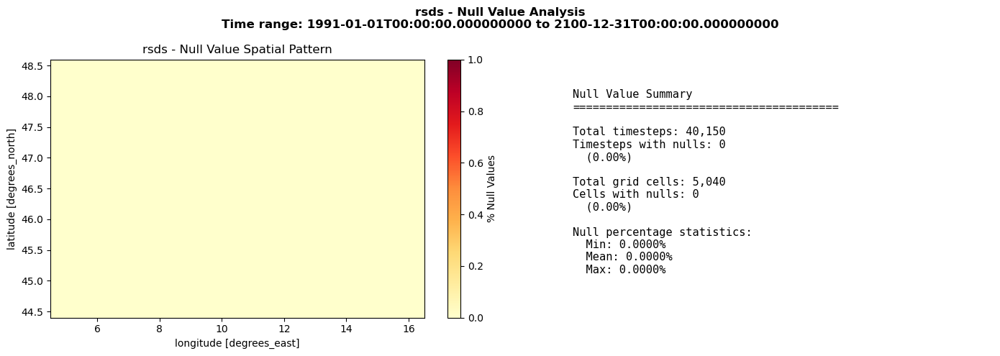

Computing null value statistics for sfcWind...
[########################################] | 100% Completed | 30.02 s
[########################################] | 100% Completed | 30.02 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


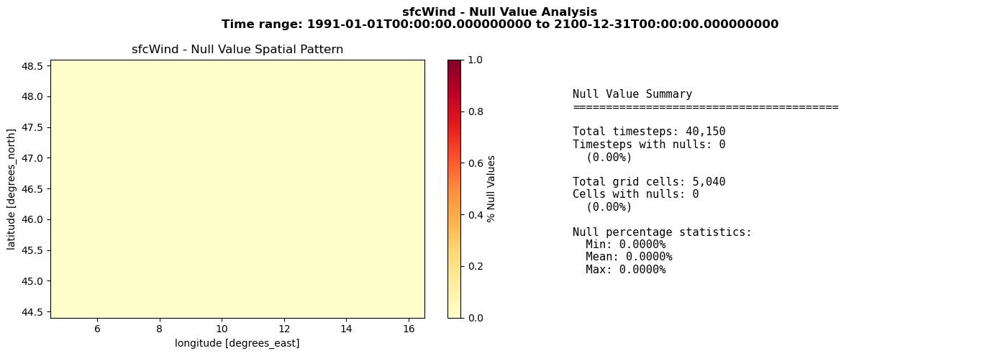

Computing null value statistics for tas...
[########################################] | 100% Completed | 50.02 s
[########################################] | 100% Completed | 50.02 s
[########################################] | 100% Completed | 15.00 s
[########################################] | 100% Completed | 15.00 s


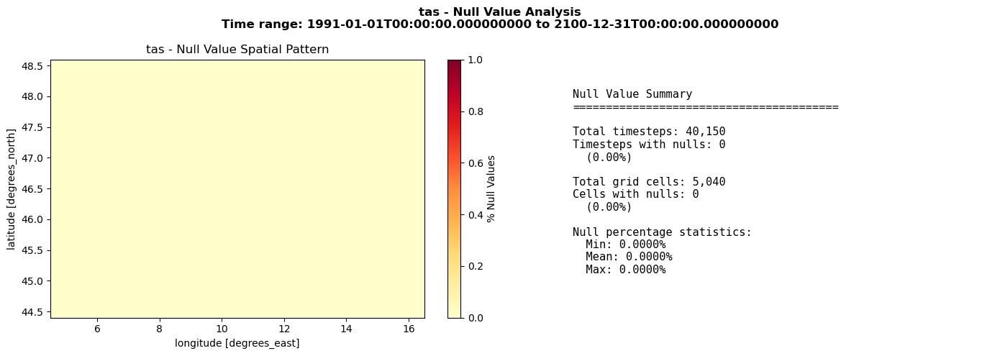

Computing null value statistics for tas_max...
[########################################] | 100% Completed | 55.02 s
[########################################] | 100% Completed | 55.02 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


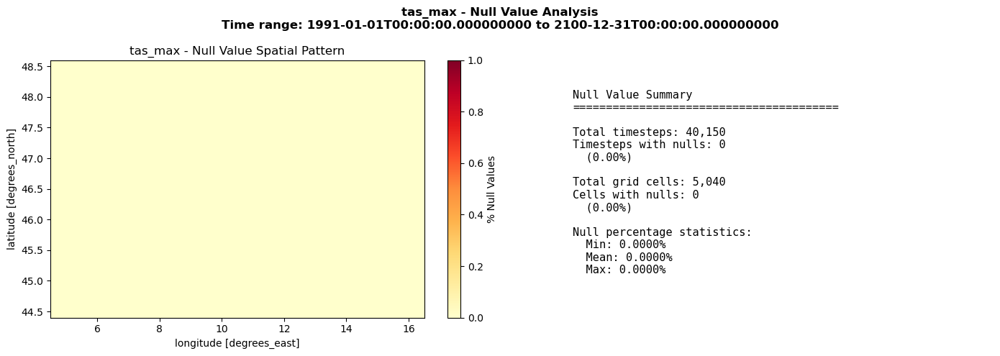

Computing null value statistics for tas_min...
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 40.01 s
[########################################] | 100% Completed | 10.00 s
[########################################] | 100% Completed | 10.00 s


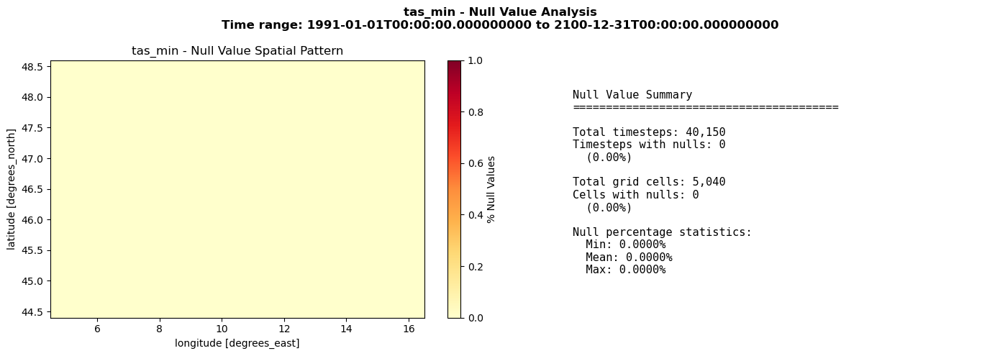

Computing null value statistics for clt...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


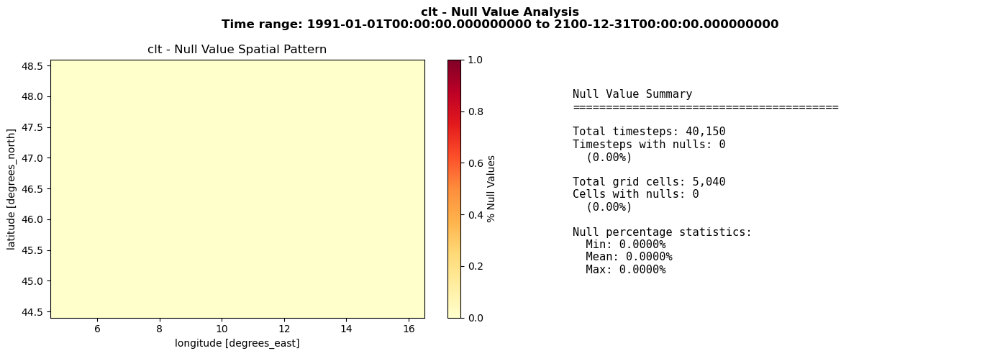

Computing null value statistics for psl...
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


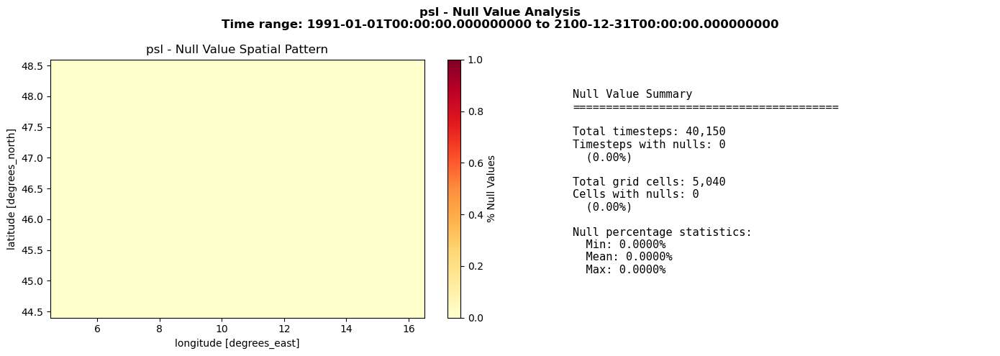

In [16]:
for var, ds in data_dict.items():
    plot_null_patterns(ds, var)

Computing spatial mean for huss...
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 40.02 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s
[########################################] | 100% Completed | 20.01 s


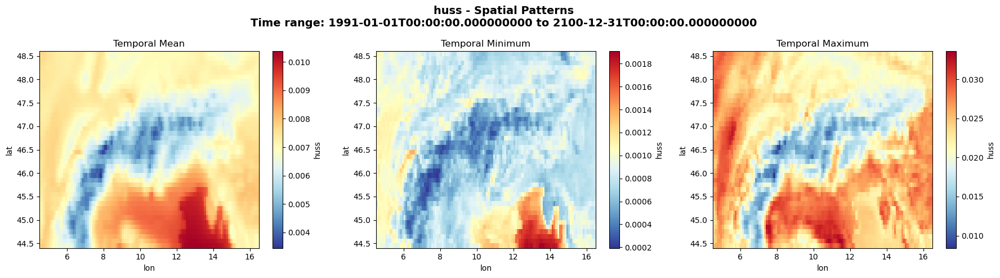


Summary Statistics for huss
Overall mean: 0.0071
Spatial range: [0.0002, 0.0336]

Computing spatial mean for hurs...
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 35.01 s
[########################################] | 100% Completed | 10.00 s
[########################################] | 100% Completed | 10.00 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s


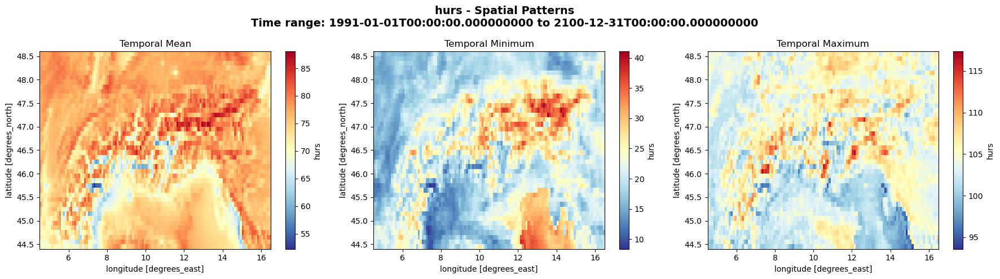


Summary Statistics for hurs
Overall mean: 75.5564
Spatial range: [8.4003, 117.3453]

Computing spatial mean for pr...
[########################################] | 100% Completed | 5.02 ss
[########################################] | 100% Completed | 5.02 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s


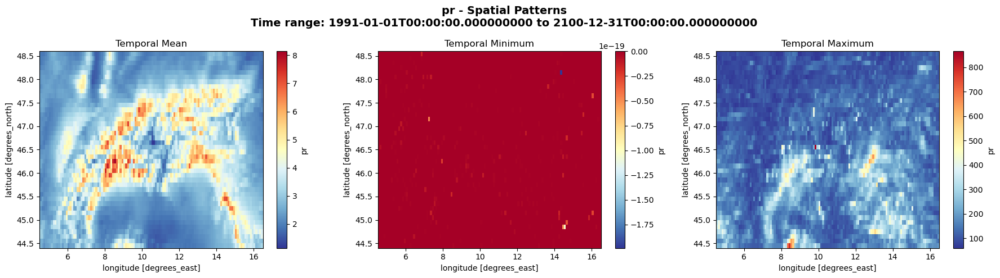


Summary Statistics for pr
Overall mean: 3.2042
Spatial range: [-0.0000, 865.7965]

Computing spatial mean for rsds...
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


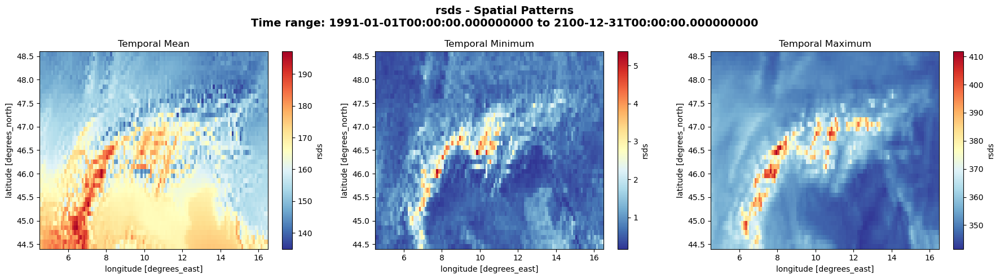


Summary Statistics for rsds
Overall mean: 159.2789
Spatial range: [0.1728, 411.7832]

Computing spatial mean for sfcWind...
[########################################] | 100% Completed | 5.03 ss
[########################################] | 100% Completed | 5.03 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s


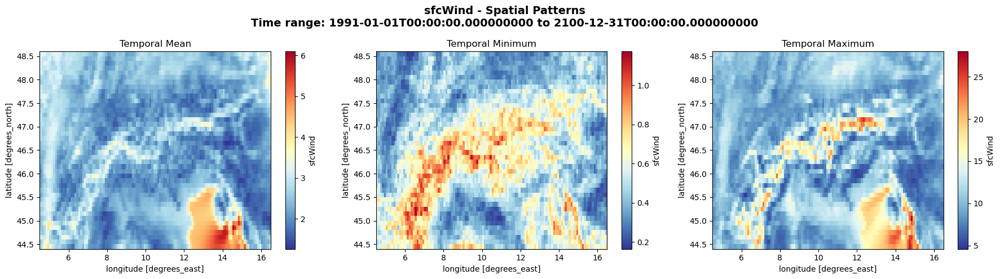


Summary Statistics for sfcWind
Overall mean: 2.4462
Spatial range: [0.1648, 27.9986]

Computing spatial mean for tas...
[########################################] | 100% Completed | 5.02 ss
[########################################] | 100% Completed | 5.02 ss
[########################################] | 100% Completed | 5.01 ss
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


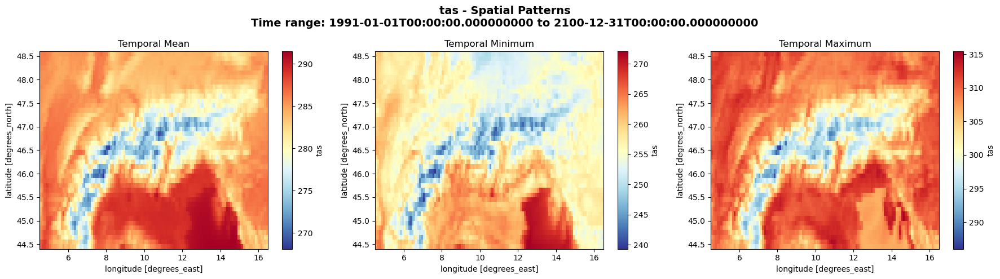


Summary Statistics for tas
Overall mean: 283.8752
Spatial range: [239.3010, 315.4019]

Computing spatial mean for tas_max...
[########################################] | 100% Completed | 5.00 ss
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s


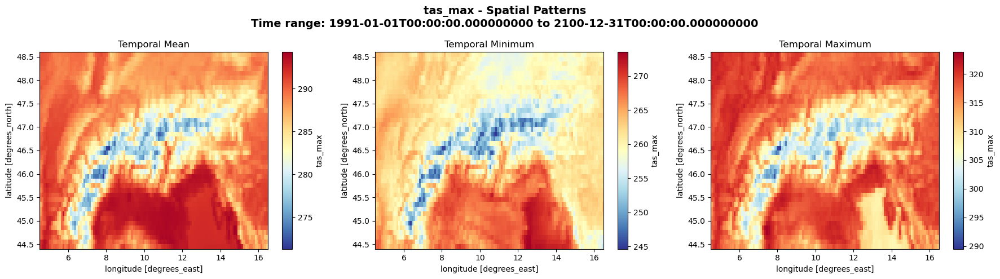


Summary Statistics for tas_max
Overall mean: 287.9013
Spatial range: [244.6257, 323.8160]

Computing spatial mean for tas_min...
[########################################] | 100% Completed | 5.01 ss
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


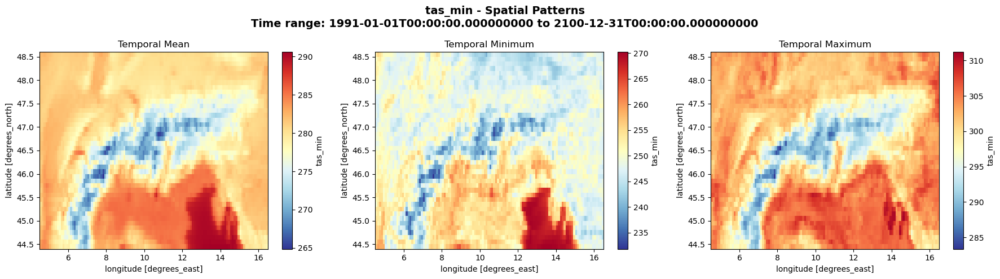


Summary Statistics for tas_min
Overall mean: 280.2347
Spatial range: [231.8582, 311.1963]

Computing spatial mean for clt...
[########################################] | 100% Completed | 5.04 ss
[########################################] | 100% Completed | 5.04 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


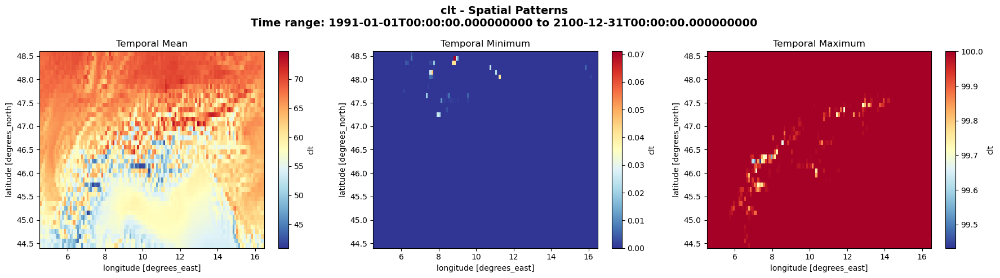


Summary Statistics for clt
Overall mean: 61.5419
Spatial range: [0.0000, 100.0000]

Computing spatial mean for psl...
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


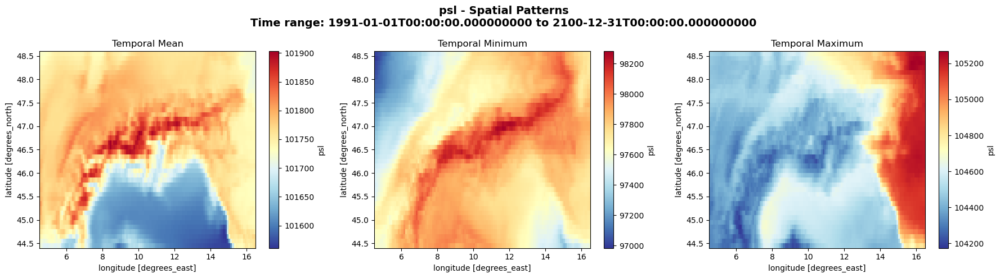


Summary Statistics for psl
Overall mean: 101740.3594
Spatial range: [96984.5312, 105267.1719]



In [17]:
for var, ds in data_dict.items():
    plot_spatial_stats(ds, var)

# CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1

## rcp26

In [20]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_model_scenario = "rcp26"

data_dict = load_prevah_data(climate_model_chain, climate_model_scenario)


Loading huss...
Loading hurs...
Loading pr...
Loading rsds...
Loading sfcWind...
Loading tas...
Loading tas_max...
Loading tas_min...
Loading clt...
Loading psl...

Loaded 10/10 variables
✓ All variables present!

huss:
  Variables: ['huss']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

hurs:
  Variables: ['hurs']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

pr:
  Variables: ['pr']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

rsds:
  Variables: ['rsds']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

sfcWind:
  Variables: ['sfcWind']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.

In [21]:
# Find timesteps where pr exceeds 500 mm/day in any grid cell
pr_ds = data_dict['pr']
pr_data = pr_ds['pr']

threshold = 400  # mm/day
print(f"Searching for timesteps with pr > {threshold} mm/day...")
with ProgressBar(dt=5):
    # Find locations where pr exceeds 500 mm/day
    extreme_mask = (pr_data > threshold).compute()
    # Get timesteps that have at least one grid cell exceeding threshold
    timesteps_with_extremes = extreme_mask.any(dim=['lat', 'lon'])
    extreme_times = pr_data.time[timesteps_with_extremes].values

    # Get max value per timestep for the extreme events
    if len(extreme_times) > 0:
        max_per_extreme_time = pr_data.sel(time=extreme_times).max(dim=['lat', 'lon']).compute()

print(f"\n{'='*60}")
print(f"Extreme Precipitation Events (> {threshold} mm/day)")
print(f"{'='*60}")
print(f"Number of timesteps with extremes: {len(extreme_times)}")
if len(extreme_times) > 0:
    print(f"\nTimesteps with pr > {threshold} mm/day:")
    for i, (time, max_val) in enumerate(zip(extreme_times, max_per_extreme_time.values)):
        print(f"  {i+1}. {time}: max = {max_val:.2f} mm/day")
else:
    print(f"No timesteps found with pr > {threshold} mm/day")
print(f"{'='*60}")

Searching for timesteps with pr > 400 mm/day...
[########################################] | 100% Completed | 60.02 s

Extreme Precipitation Events (> 400 mm/day)
Number of timesteps with extremes: 0
No timesteps found with pr > 400 mm/day


Computing null value statistics for huss...
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 10.01 s


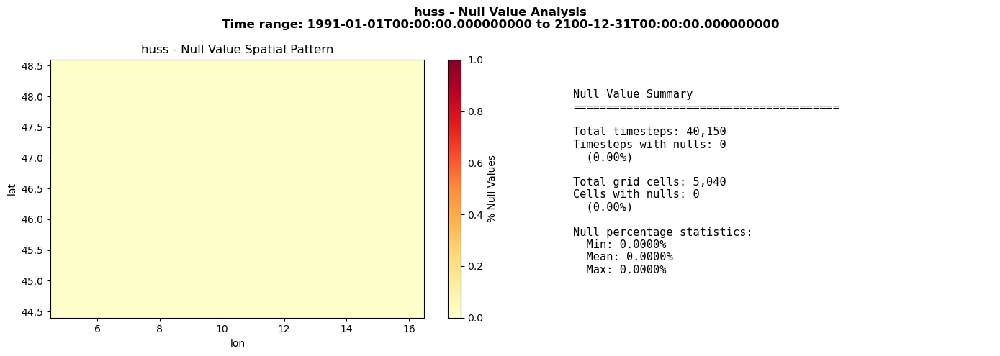

Computing null value statistics for hurs...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 15.01 s


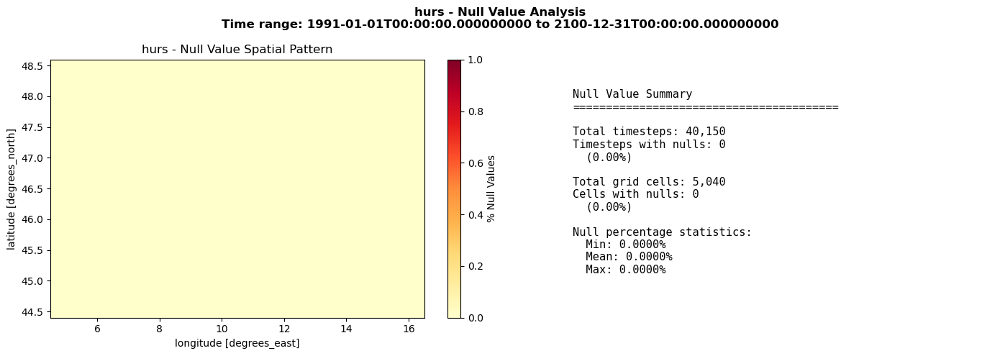

Computing null value statistics for pr...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 10.00 s


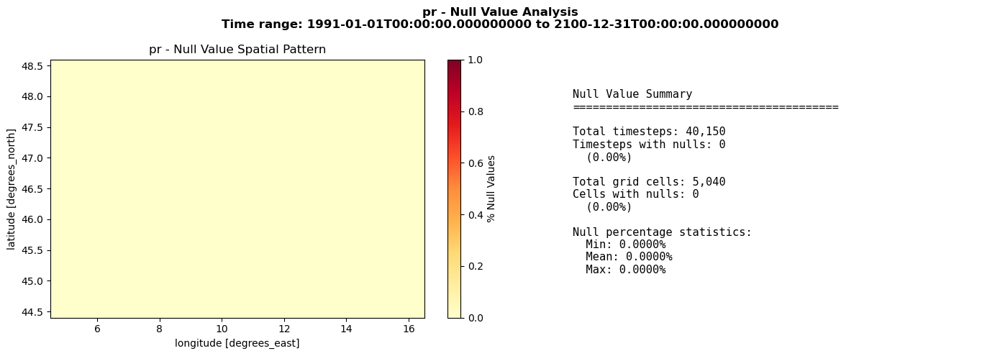

Computing null value statistics for rsds...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 5.01 s


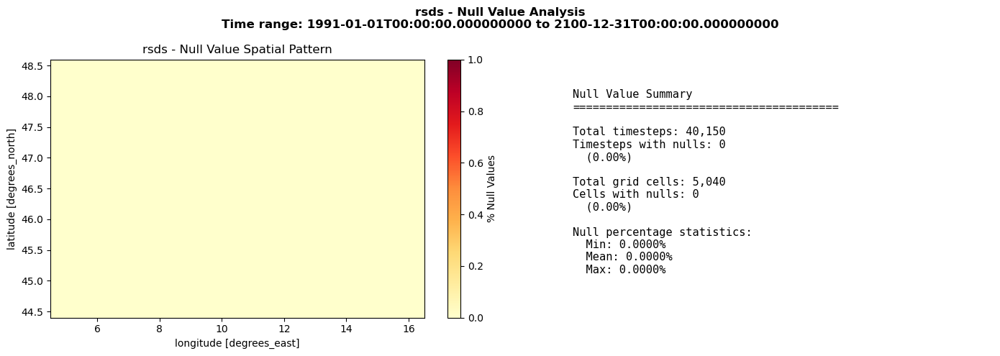

Computing null value statistics for sfcWind...
[########################################] | 100% Completed | 10.00 s
[########################################] | 100% Completed | 5.00 s


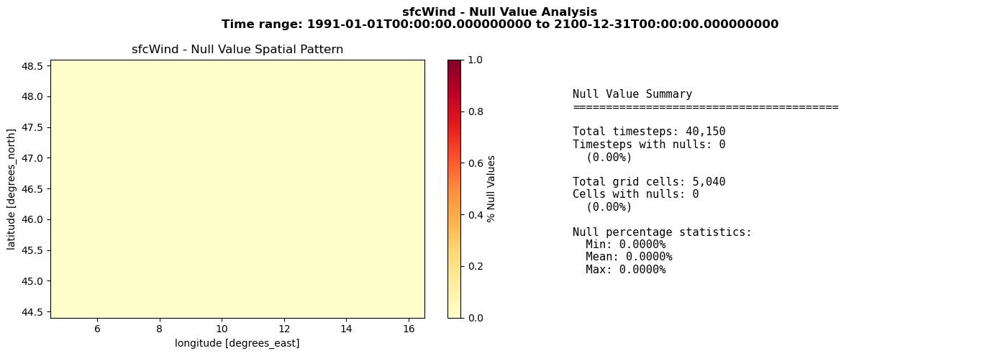

Computing null value statistics for tas...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 5.01 s


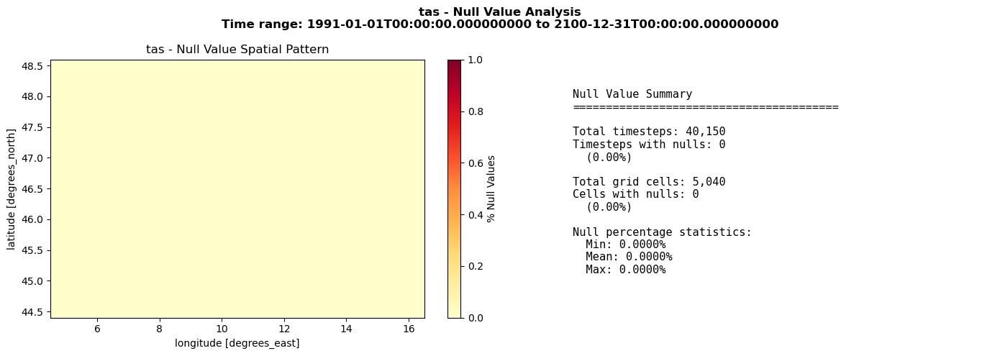

Computing null value statistics for tas_max...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 5.01 s


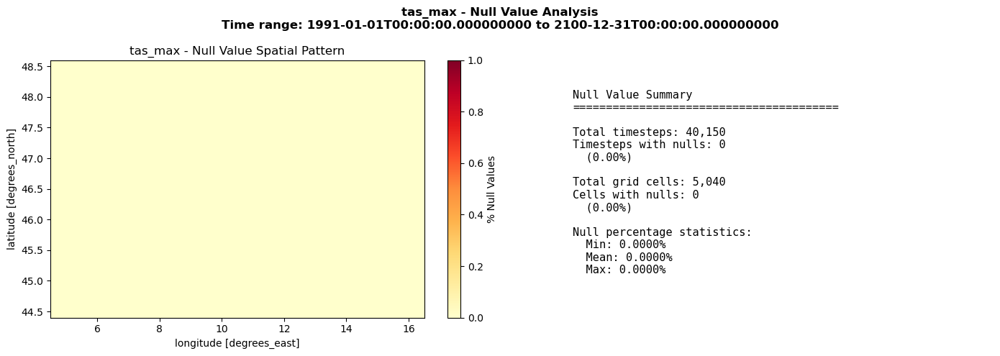

Computing null value statistics for tas_min...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 5.01 s


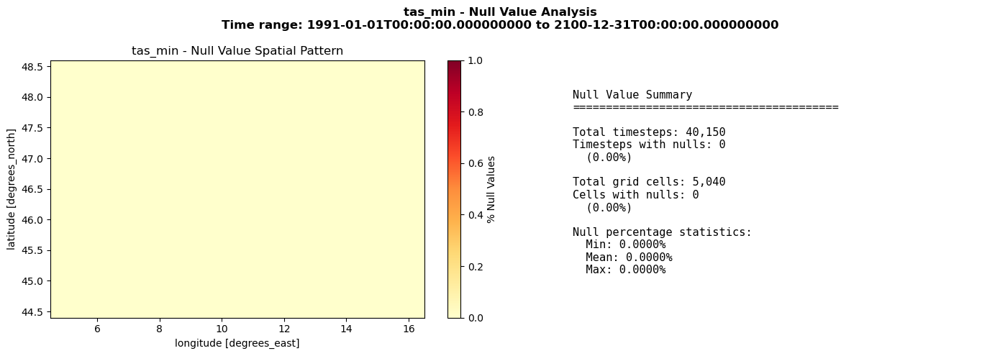

Computing null value statistics for clt...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 10.01 s


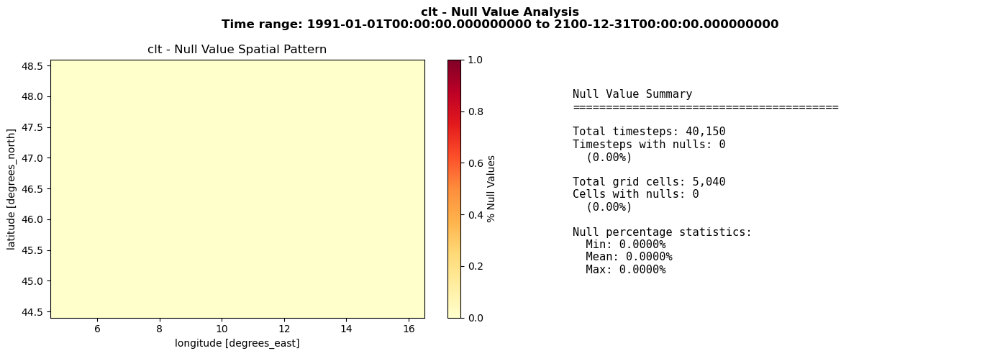

Computing null value statistics for psl...
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 5.01 ss


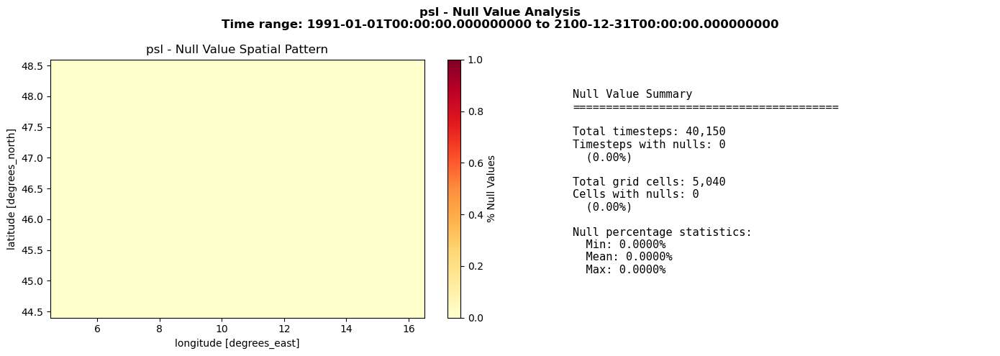

In [10]:
for var, ds in data_dict.items():
    plot_null_patterns(ds, var)

Computing spatial mean for huss...
[                                        ] | 0% Completed | 2.99 ms

[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.00 ss


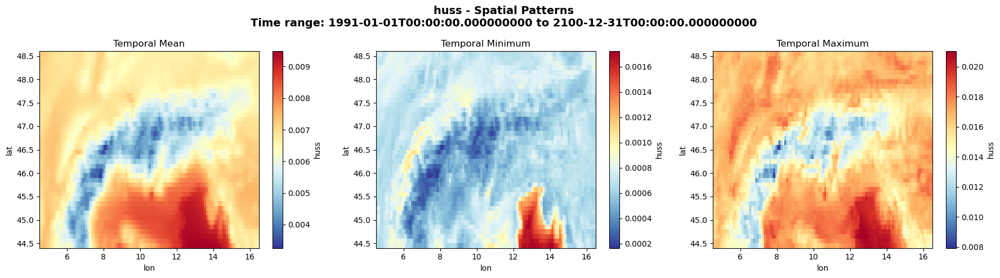


Summary Statistics for huss
Overall mean: 0.0067
Spatial range: [0.0002, 0.0210]

Computing spatial mean for hurs...
[########################################] | 100% Completed | 15.00 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s


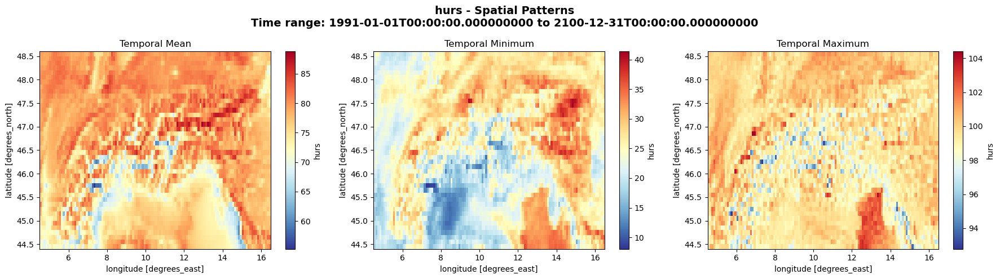


Summary Statistics for hurs
Overall mean: 77.2986
Spatial range: [8.0546, 104.3932]

Computing spatial mean for pr...
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s


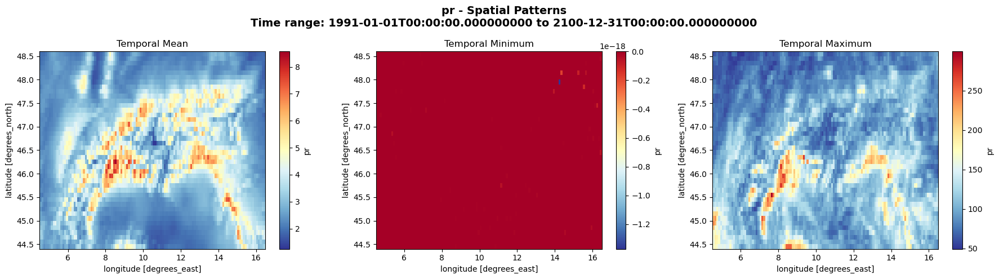


Summary Statistics for pr
Overall mean: 3.3042
Spatial range: [-0.0000, 299.4142]

Computing spatial mean for rsds...
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s


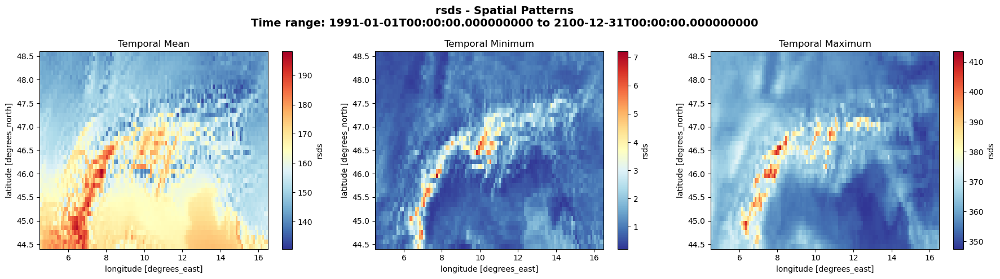


Summary Statistics for rsds
Overall mean: 156.6360
Spatial range: [0.2171, 413.4934]

Computing spatial mean for sfcWind...
[########################################] | 100% Completed | 5.03 ss
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s


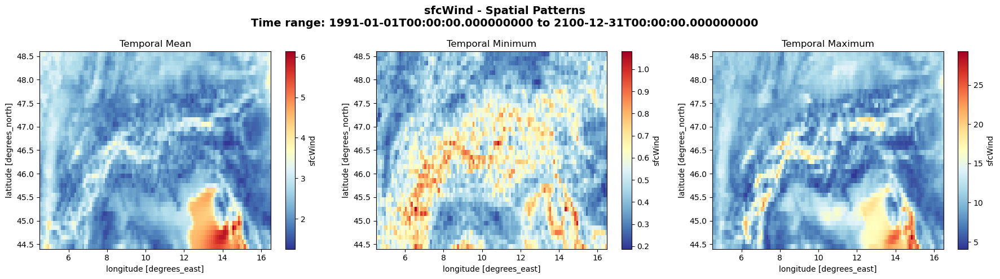


Summary Statistics for sfcWind
Overall mean: 2.4455
Spatial range: [0.1879, 29.2652]

Computing spatial mean for tas...
[########################################] | 100% Completed | 5.02 ss
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.00 s


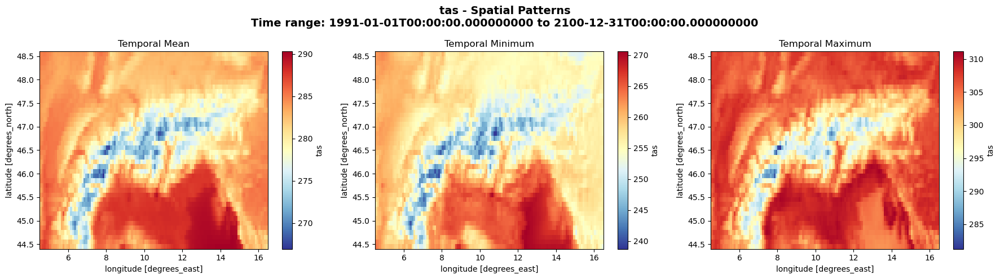


Summary Statistics for tas
Overall mean: 282.5822
Spatial range: [238.7420, 311.1324]

Computing spatial mean for tas_max...
[########################################] | 100% Completed | 5.03 ss
[########################################] | 100% Completed | 5.00 ss
[########################################] | 100% Completed | 5.01 s


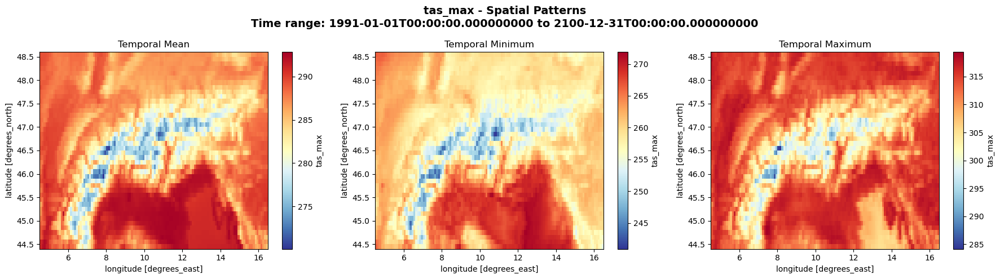


Summary Statistics for tas_max
Overall mean: 286.5634
Spatial range: [240.9263, 319.3956]

Computing spatial mean for tas_min...
[########################################] | 100% Completed | 5.01 ss
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s


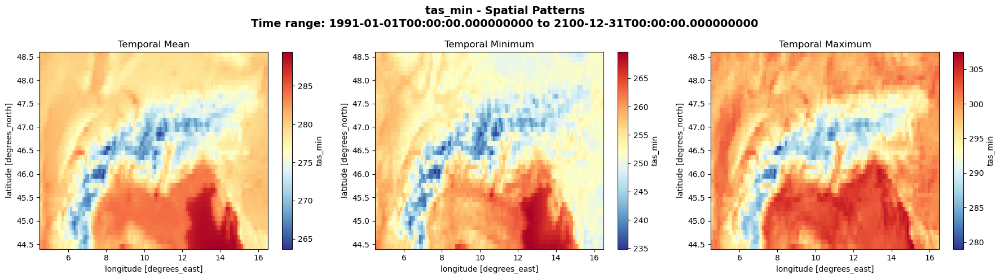


Summary Statistics for tas_min
Overall mean: 278.9422
Spatial range: [234.8738, 307.4736]

Computing spatial mean for clt...
[########################################] | 100% Completed | 5.03 ss
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


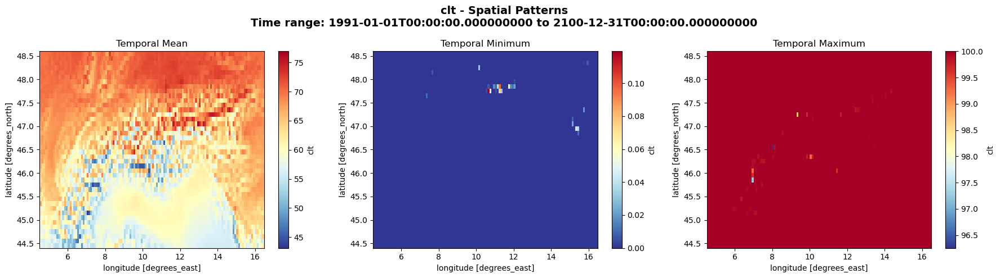


Summary Statistics for clt
Overall mean: 63.8511
Spatial range: [0.0000, 100.0000]

Computing spatial mean for psl...
[########################################] | 100% Completed | 5.01 ss
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s


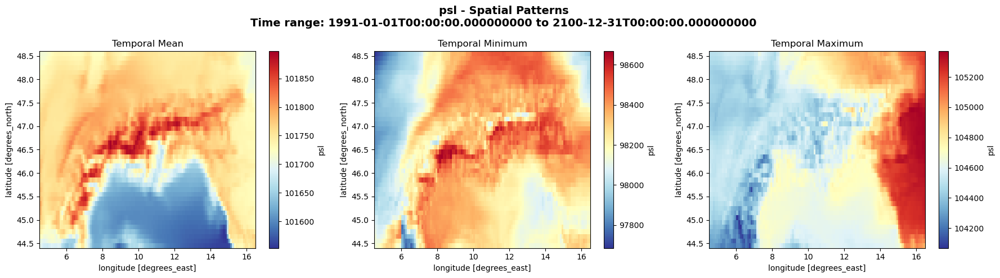


Summary Statistics for psl
Overall mean: 101732.0781
Spatial range: [97684.9922, 105369.9219]



In [11]:
for var, ds in data_dict.items():
    plot_spatial_stats(ds, var)

## rcp85

In [12]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_model_scenario = "rcp85"

data_dict = load_prevah_data(climate_model_chain, climate_model_scenario)


Loading huss...
Loading hurs...
Loading pr...
Loading rsds...
Loading sfcWind...
Loading tas...
Loading tas_max...
Loading tas_min...
Loading clt...
Loading psl...

Loaded 10/10 variables
✓ All variables present!

huss:
  Variables: ['huss']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

hurs:
  Variables: ['hurs']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

pr:
  Variables: ['pr']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

rsds:
  Variables: ['rsds']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.000000000

sfcWind:
  Variables: ['sfcWind']
  Dimensions: {'lat': 42, 'lon': 120, 'time': 40150}
  Time range: 1991-01-01T00:00:00.000000000 to 2100-12-31T00:00:00.

Computing null value statistics for huss...
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.00 s


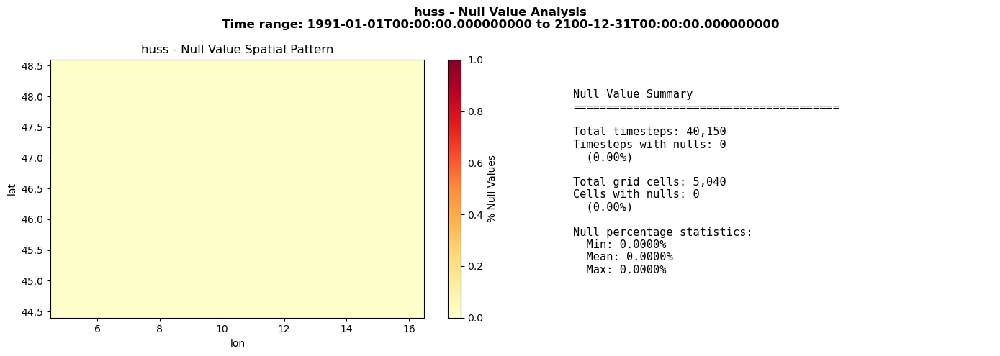

Computing null value statistics for hurs...
[                                        ] | 0% Completed | 245.00 us

[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 5.01 s


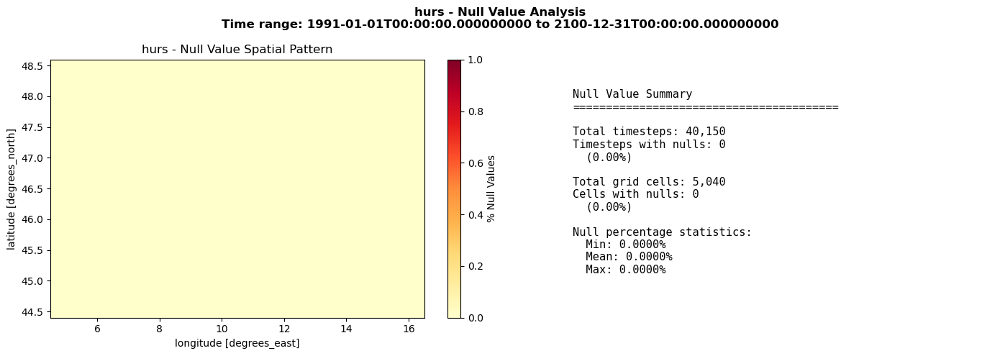

Computing null value statistics for pr...
[########################################] | 100% Completed | 10.00 s
[########################################] | 100% Completed | 5.00 s


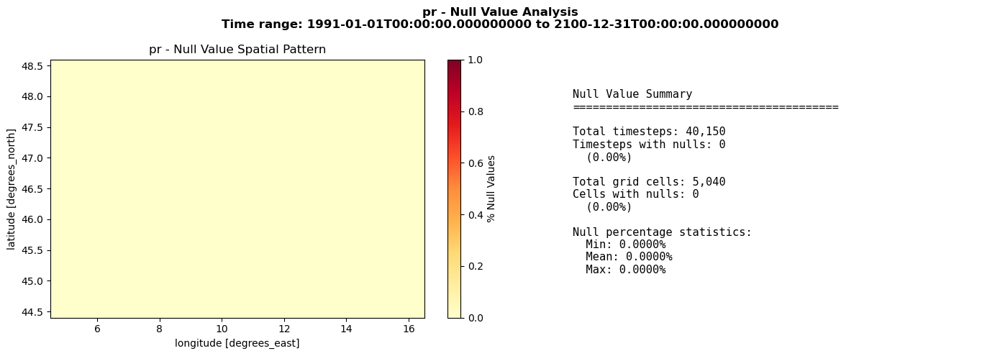

Computing null value statistics for rsds...
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s


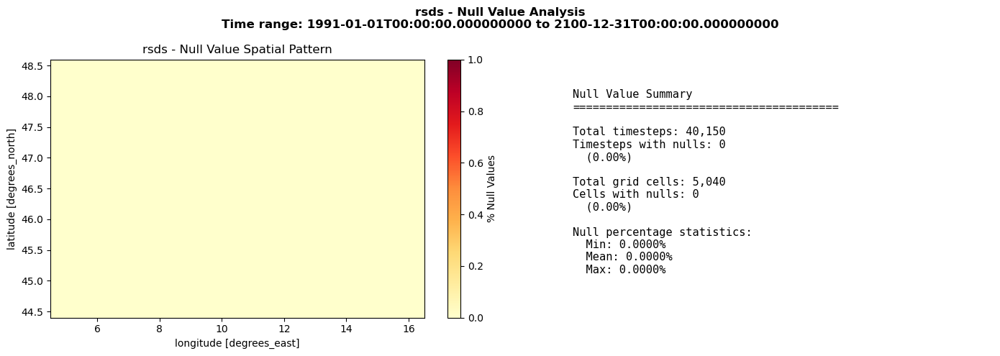

Computing null value statistics for sfcWind...
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.00 s


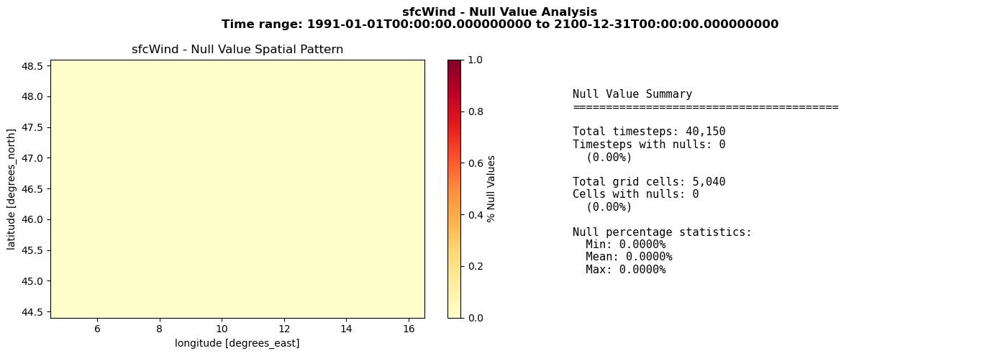

Computing null value statistics for tas...
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 5.01 s


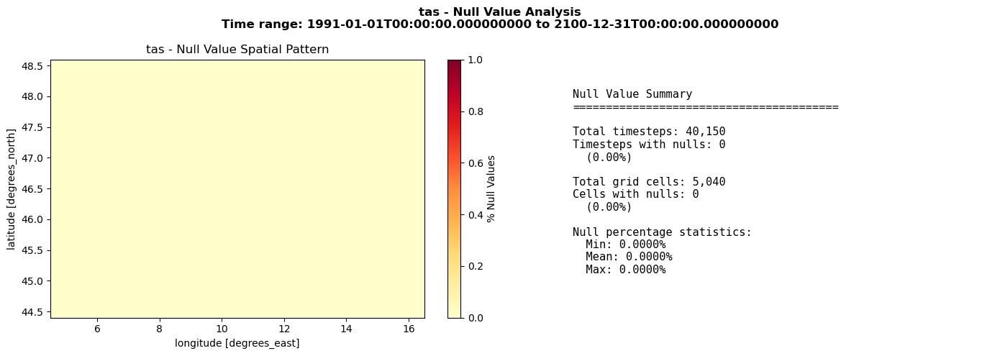

Computing null value statistics for tas_max...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 5.00 s


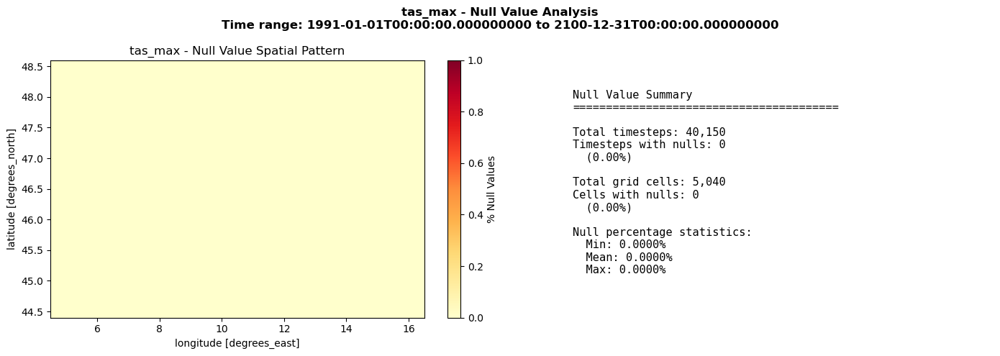

Computing null value statistics for tas_min...
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 5.01 s


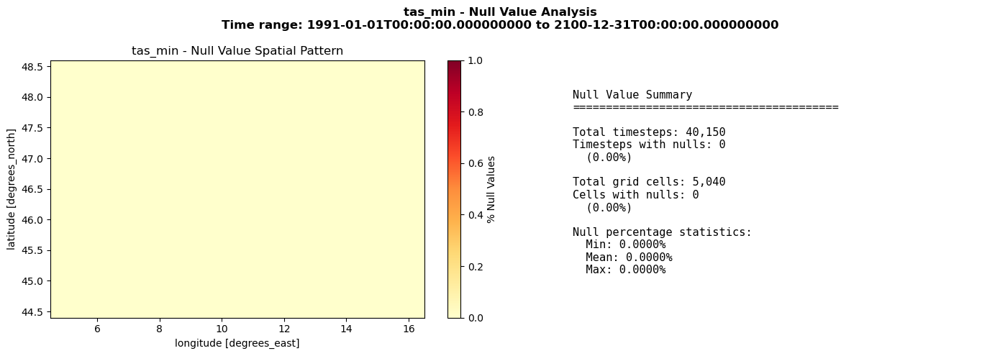

Computing null value statistics for clt...
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 5.00 s


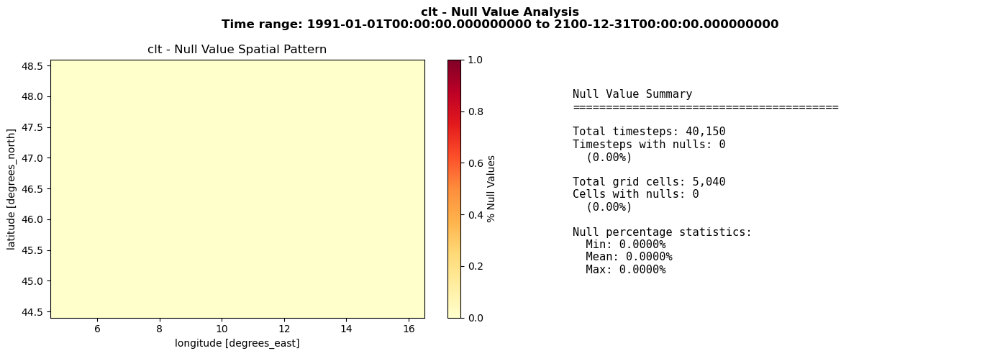

Computing null value statistics for psl...
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.00 s


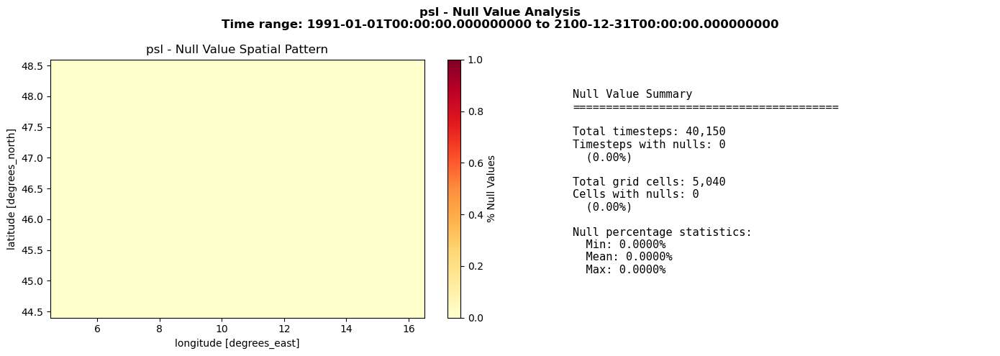

In [13]:
for var, ds in data_dict.items():
    plot_null_patterns(ds, var)

Computing spatial mean for huss...
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s


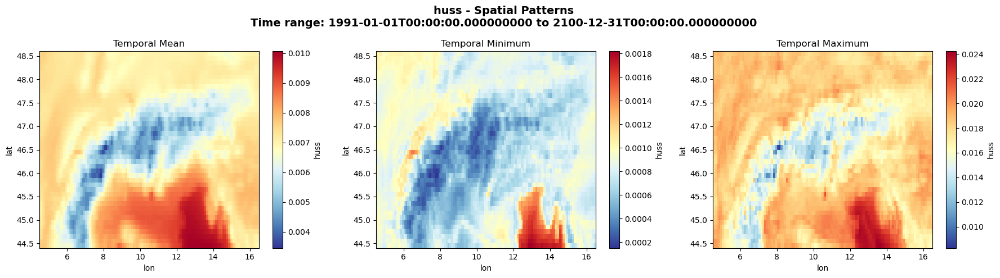


Summary Statistics for huss
Overall mean: 0.0071
Spatial range: [0.0002, 0.0242]

Computing spatial mean for hurs...
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 5.00 ss
[########################################] | 100% Completed | 5.01 s


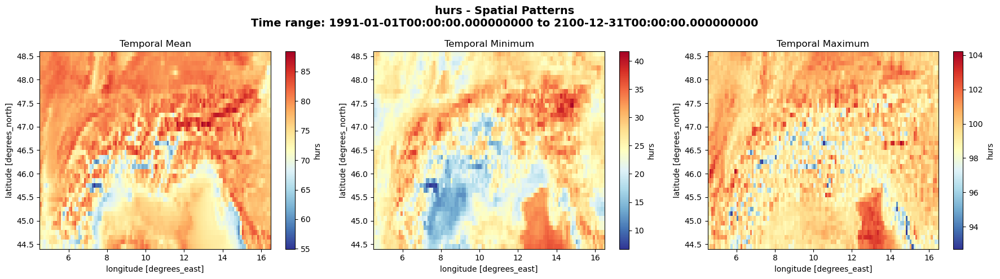


Summary Statistics for hurs
Overall mean: 76.9660
Spatial range: [6.7201, 104.2041]

Computing spatial mean for pr...
[########################################] | 100% Completed | 5.00 s
[#################################       ] | 83% Completed | 5.01 s

[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 10.01 s


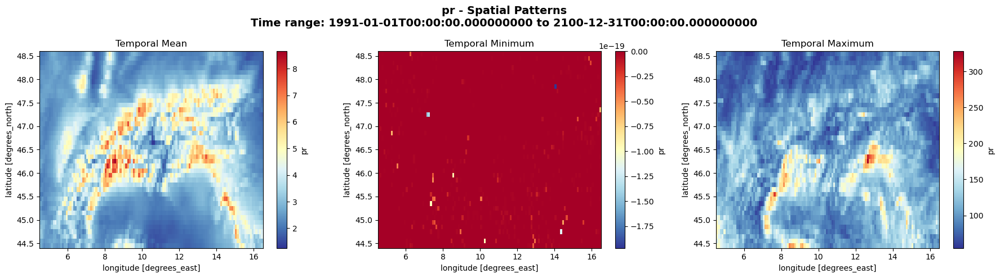


Summary Statistics for pr
Overall mean: 3.3200
Spatial range: [-0.0000, 328.0172]

Computing spatial mean for rsds...
[########################################] | 100% Completed | 5.03 ss
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 10.00 s


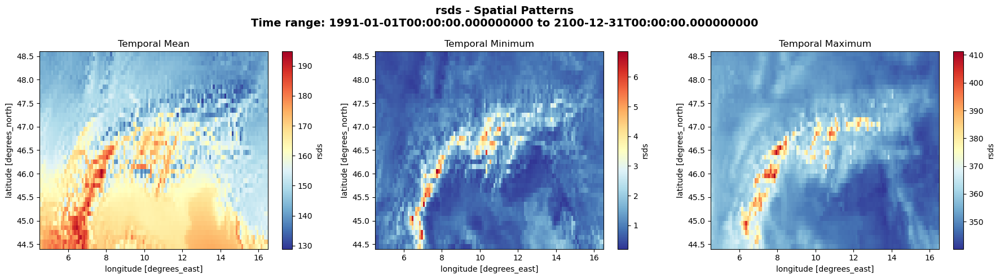


Summary Statistics for rsds
Overall mean: 155.7290
Spatial range: [0.2091, 411.2225]

Computing spatial mean for sfcWind...
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 20.01 s


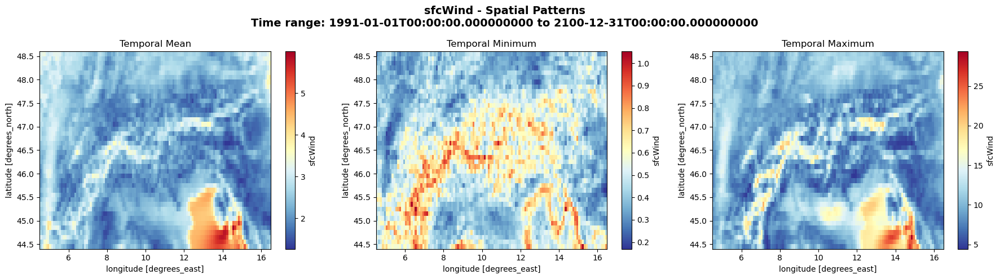


Summary Statistics for sfcWind
Overall mean: 2.4277
Spatial range: [0.1699, 29.3776]

Computing spatial mean for tas...
[########################################] | 100% Completed | 5.01 ss
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.00 ss


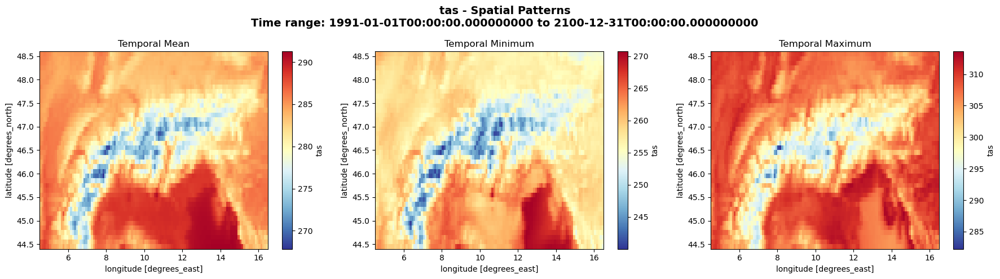


Summary Statistics for tas
Overall mean: 283.5352
Spatial range: [240.0272, 313.6083]

Computing spatial mean for tas_max...
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 10.01 s
[########################################] | 100% Completed | 5.00 s


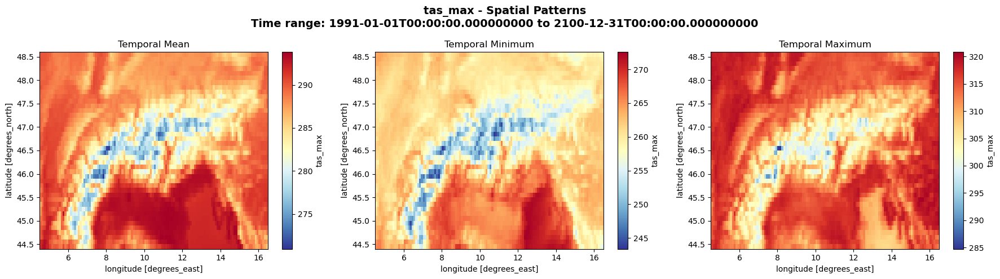


Summary Statistics for tas_max
Overall mean: 287.5708
Spatial range: [243.3799, 320.8324]

Computing spatial mean for tas_min...
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 5.01 s
[########################################] | 100% Completed | 5.01 s


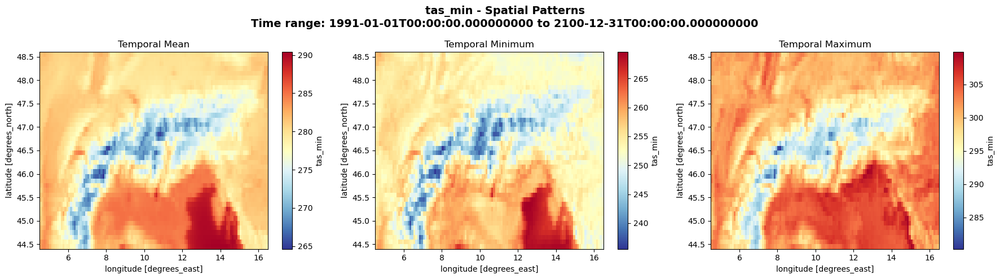


Summary Statistics for tas_min
Overall mean: 279.8824
Spatial range: [235.5447, 309.8741]

Computing spatial mean for clt...
[########################################] | 100% Completed | 20.03 s
[########################################] | 100% Completed | 5.00 s
[########################################] | 100% Completed | 10.01 s


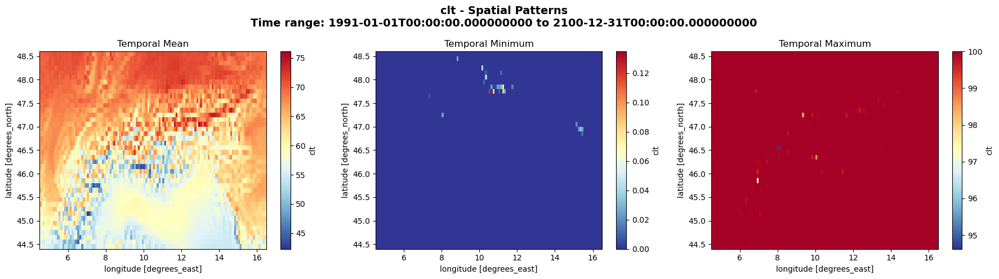


Summary Statistics for clt
Overall mean: 62.9140
Spatial range: [0.0000, 100.0000]

Computing spatial mean for psl...
[########################################] | 100% Completed | 15.01 s
[########################################] | 100% Completed | 10.00 s
[########################################] | 100% Completed | 5.01 s


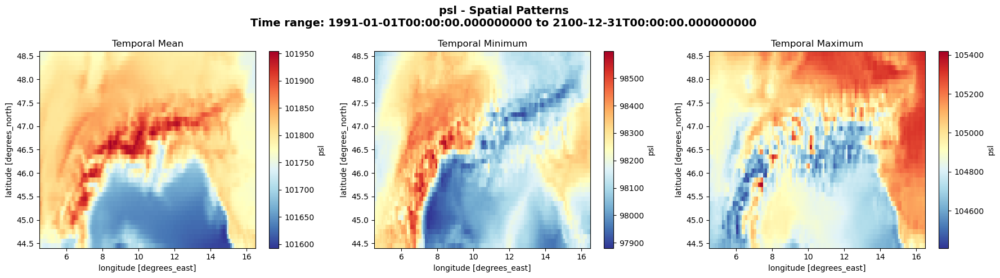


Summary Statistics for psl
Overall mean: 101779.6406
Spatial range: [97880.7422, 105418.1641]



In [14]:
for var, ds in data_dict.items():
    plot_spatial_stats(ds, var)